# magnetOrbits: progress summary (stages 0–9)

Scattering and capture of two free, spinning, uniformly magnetized spheres. This notebook
walks through each validated stage of [PLAN.md](../PLAN.md): the model, a single trajectory,
the exact power-law (central-force) limit, rotor dynamics, conservation laws, the asymptotic
in-state, the reference-paper configuration, the in-plane orientation map, and the compiled
integrator. It ends with a summary of results and the next steps.

**Every physics function is imported from `physics/`** (and the validated test cases from
`tests/`); the notebook contains only plotting and glue code. Run it top to bottom with
*Restart & Run All* (about a minute; the first compiled call takes a few extra seconds).

| Section | Stage | What is checked |
|---|---|---|
| 1. Model | 1 | force $=-\nabla U$, torque balance, dimensionless scales |
| 2. One trajectory | 2 | interactive single run: path, energy and angular-momentum exchange |
| 3. Power-law limit | 2–3 | deflection vs quadrature, small-angle limit, capture edge $b_c(\tilde{E})$, orbiting, $r_0$ convergence |
| 4. Rotor dynamics | 4 | normal modes, scissor instability |
| 5. Conservation in 3D | 4 | $E$, $\mathbf{J}$ conserved; $\mathbf{L}$ exchanges with spin |
| 6. Asymptotic in-state | 5 | $r_0$ convergence order 1 → 2 |
| 7. Paper configuration | 5 | head-to-tail edge vs locked-dipole model and arXiv:2212.00876 |
| 8. Orientation map | 6b | outer edge and interval structure over $(\phi_1,\phi_2)$ |
| 9. Compiled integrator | 7 | numba path = scipy path, speedup |
| 10. Zoomed maps, fractal boundary | 8 | antiparallel cusp, window band, tail-to-tail corner, uncertainty exponent |
| 11. Collision edge vs. energy | 6a | head-to-tail and orientation-averaged edge vs the locked law; slow and fast limits |
| 12. Window band vs. energy | 9 | band position, size and fractal dimension across $\tilde E$ |
| 13. Summary and next steps | | |

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

# Repository root: $MAGNETORBITS_ROOT if set, else the first parent of the working directory
# that contains physics/ (works when opened from notebooks/ or from the repository root).
ROOT = Path(os.environ["MAGNETORBITS_ROOT"]) if "MAGNETORBITS_ROOT" in os.environ else next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "physics").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt

from physics import central, observables
from physics.model import (SphereParams, force_on_2, potential, torques, scales,
                           physical_to_dimensionless, CONTACT_SEPARATION)
from physics.solve import run_trajectory, integrate_state
from physics.capture import find_capture_edge
from physics.edges import in_plane_moment, in_plane_profile
from tests.published.bartz_shaw_2022 import ENERGY_TILDE as E_PAPER, TARGET_MAX_IMPACT_PARAMETER

# Plot style (project convention): no titles, no gridlines, large fonts.
plt.rcParams.update({"font.size": 14, "axes.labelsize": 16, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 12, "axes.grid": False,
                     "legend.frameon": False, "figure.dpi": 100})

INERTIA = SphereParams().inertia_tilde           # I / ((m/2) R^2) = 2 beta = 4/5
Z = np.array([0.0, 0.0, 1.0])
X_HAT = np.array([1.0, 0.0, 0.0])
FAST = "numba"                                   # compiled path (stage 7), validated against scipy

git_hash = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT,
                          capture_output=True, text=True).stdout.strip()
git_dirty = bool(subprocess.run(["git", "status", "--porcelain", "physics"], cwd=ROOT,
                                capture_output=True, text=True).stdout)
t0 = time.time()
run_trajectory(0.03, 5.0, Z, -Z, method=FAST)   # compile / load the numba cache once
print(f"code version {git_hash}{' (physics/ modified)' if git_dirty else ''}; "
      f"numba ready in {time.time() - t0:.1f} s; paper energy E = {E_PAPER:.6f}")

code version 238f5c2; numba ready in 0.2 s; paper energy E = 0.033501


## 1. Model and dimensionless variables (stage 1)

Two identical spheres of mass $m$, radius $R$, dipole moment $\mu$ and moment of inertia
$I=\beta mR^2$ ($\beta=2/5$). A uniformly magnetized sphere is exactly a point dipole outside
itself, so the interaction is the dipole–dipole one. There is no contact force: reaching
$r=2R$ counts as a **collision** and ends the run.

Scales: length $R$, energy $U_0=\mu_0\mu^2/4\pi R^3$, mass $m/2$ (reduced mass), time
$t_0=\sqrt{(m/2)R^2/U_0}$. With $\mathbf{r}=\mathbf{r}_2-\mathbf{r}_1$ and unit moments
$\hat{\mu}_i$,

$$
U=-\frac{1}{r^3}\Big[3(\hat{\mu}_1\cdot\hat{r})(\hat{\mu}_2\cdot\hat{r})-\hat{\mu}_1\cdot\hat{\mu}_2\Big],
\qquad
\ddot{\mathbf{r}}=\mathbf{F}_2=-\nabla U,
\qquad
\dot{\hat{\mu}}_i=\boldsymbol\omega_i\times\hat{\mu}_i,
\qquad
\tilde{I}\,\dot{\boldsymbol\omega}_i=\boldsymbol\tau_i=\hat{\mu}_i\times\mathbf{B}_j ,
$$

with $\tilde{I}=2\beta=4/5$. The total angular momentum
$\mathbf{J}=\mathbf{r}\times\dot{\mathbf{r}}+\tilde{I}(\boldsymbol\omega_1+\boldsymbol\omega_2)$
is conserved because $\boldsymbol\tau_1+\boldsymbol\tau_2+\mathbf{r}\times\mathbf{F}_2=0$; the
orbital part alone is not.

The remaining inputs are $\tilde{E}$ (relative kinetic energy $/U_0$), $\tilde{b}=b/R$ and the
initial moment directions. For uniformly magnetized spheres
$\tilde{E}=\tfrac34\rho v_{\rm rel}^2/\mu_0M^2$: **the sphere size drops out**.

The cell below re-checks the model functions: the force against a finite-difference gradient
of $U$, and the torque balance, at random configurations.

In [2]:
rng = np.random.default_rng(0)
def random_unit():
    v = rng.normal(size=3)
    return v / np.linalg.norm(v)

force_err, balance_err, h = 0.0, 0.0, 1e-6
for _ in range(500):
    r_vec, m1, m2 = rng.uniform(2, 6) * random_unit(), random_unit(), random_unit()
    grad = np.array([(potential(r_vec + h * e, m1, m2) - potential(r_vec - h * e, m1, m2)) / (2 * h)
                     for e in np.eye(3)])
    F = force_on_2(r_vec, m1, m2)
    force_err = max(force_err, np.max(np.abs(F + grad)) / np.max(np.abs(F)))
    t1, t2 = torques(r_vec, m1, m2)
    balance_err = max(balance_err, np.linalg.norm(t1 + t2 + np.cross(r_vec, F))
                      / (np.linalg.norm(t1) + np.linalg.norm(t2)))
print(f"force vs -grad U (finite differences): max rel error {force_err:.1e}")
print(f"tau1 + tau2 + r x F = 0:              max rel error {balance_err:.1e}")

# Physical scales for the magnets of arXiv:2212.00876 (5 mm radius NdFeB, 4 g, 0.46 A m^2).
s = scales(mass=4e-3, radius=5e-3, moment=0.46)
E_ex, b_ex = physical_to_dimensionless(4e-3, 5e-3, 0.46, v_rel=2 * 1.16, impact_parameter=20e-3)
print(f"\nU0 = {s['energy_scale']:.3f} J, t0 = {s['time_scale']*1e3:.2f} ms, R/t0 = {s['velocity_scale']:.2f} m/s")
print(f"each sphere at 1.16 m/s, b = 20 mm  ->  E_tilde = {E_ex:.4f}, b/R = {b_ex:.1f}")

force vs -grad U (finite differences): max rel error 1.8e-09
tau1 + tau2 + r x F = 0:              max rel error 9.3e-16

U0 = 0.169 J, t0 = 0.54 ms, R/t0 = 9.20 m/s
each sphere at 1.16 m/s, b = 20 mm  ->  E_tilde = 0.0318, b/R = 4.0


In the exactly central case (moments along $+z$ and $-z$, motion in the $xy$ plane) and in the
locked head-to-tail limit, the interaction reduces to $U=-\kappa/r^3$ with $\kappa=1$ and
$\kappa=2$. The effective potential $U_{\rm eff}=\ell^2/2r^2-\kappa/r^3$ has a barrier at
$r^*=3\kappa/\ell^2$ and **no minimum**, so there are no bound orbits: the only outcomes are
escape and collision. Collision requires crossing the barrier, unless the barrier lies inside
contact ($r^*<2$), in which case reaching $r=2$ is enough:

- $\tilde{b}_c=(27\kappa^2/4)^{1/6}\tilde{E}^{-1/3}$ for $\tilde{E}<\kappa/16$ (barrier-limited),
- $\tilde{b}_c=\sqrt{4+\kappa/2\tilde{E}}$ for $\tilde{E}>\kappa/16$ (contact-limited).

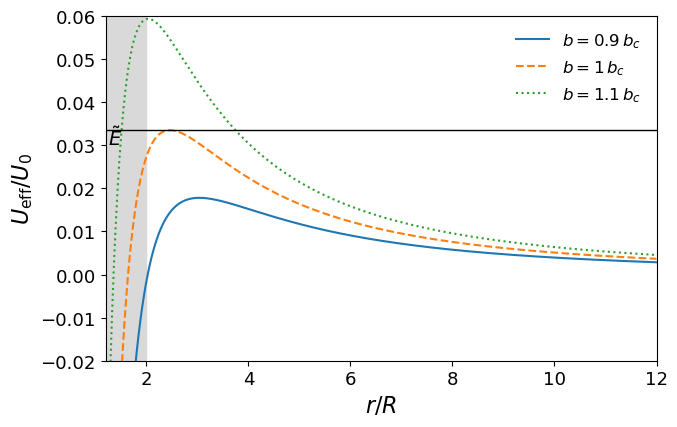

shaded: r < 2R (spheres overlap). At b = b_c the barrier top equals E.


In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
r = np.linspace(1.2, 12, 600)
kappa, energy = 1.0, E_PAPER
for factor, style in [(0.9, "-"), (1.0, "--"), (1.1, ":")]:
    b = factor * central.capture_impact_parameter(energy, kappa)
    ell_sq = 2 * energy * b**2
    ax.plot(r, ell_sq / (2 * r**2) - kappa / r**3, style, label=fr"$b={factor:g}\,b_c$")
ax.axhline(energy, color="k", lw=1)
ax.axvspan(0, CONTACT_SEPARATION, color="0.85")
ax.text(1.25, 0.9 * energy, r"$\tilde{E}$", fontsize=14)
ax.set_xlim(1.2, 12); ax.set_ylim(-0.02, 0.06)
ax.set_xlabel(r"$r/R$"); ax.set_ylabel(r"$U_{\rm eff}/U_0$")
ax.legend(); fig.tight_layout(); plt.show()
print("shaded: r < 2R (spheres overlap). At b = b_c the barrier top equals E.")

## 2. A single trajectory (stage 2)

`run_trajectory` is the one code path used by every run and every sweep. Its in-state starts
the relative coordinate at $r_0=1000$ on the line $y=b$, with speed and offset chosen so that
the energy and orbital angular momentum at infinity are exactly $\tilde{E}$ and
$b\sqrt{2\tilde{E}}$. The moments are specified at $t\to-\infty$ (see Section 6). The run ends
at contact ($r=2$), at the **rigorous** escape criterion
($\dot{r}>0$ and $\tfrac12\dot{r}^2>2/r^3$, since the radial force is at least $-6/r^4$), or at
$r_{\rm out}$ if the asymptotic deflection is wanted.

Below, the head-to-tail configuration of the reference paper at its energy. The spheres start
with no spin; the torque spins them up, trading orbital for spin angular momentum while
$J_z$ stays fixed. The left panel shows both spheres in the center-of-mass frame
($\mathbf{r}_{1,2}=\mp\mathbf{r}/2$), with each moment direction drawn along its sphere's path and the
spheres shaded at closest approach.

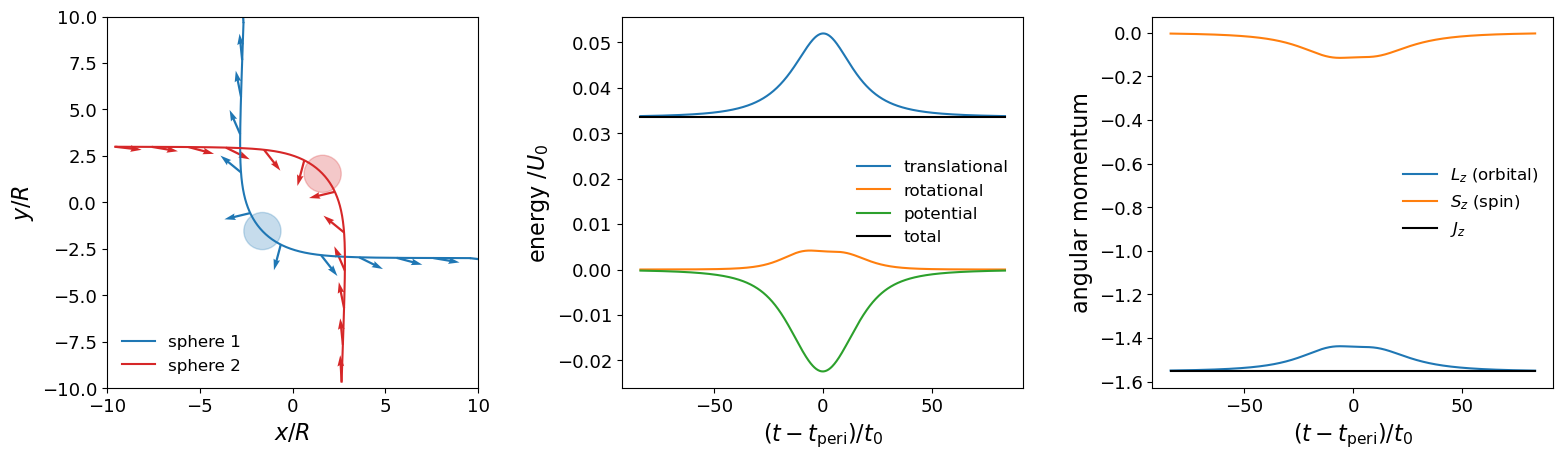

outcome escape  (contact via None)  r_min = 4.4691  deflection (3D) = 1.6081 rad
drifts: energy 1.2e-11, J 1.3e-12, | |m| - 1 | 1.5e-11   (1817 RHS evaluations)


In [4]:
def moment_direction(phi, tilt=0.0):
    '''Unit moment at azimuth phi (from +x, the incoming direction) and elevation tilt out of the plane.'''
    return np.array([np.cos(tilt) * np.cos(phi), np.cos(tilt) * np.sin(phi), np.sin(tilt)])


def show_trajectory(energy=E_PAPER, b=6.0, phi1=0.0, phi2=0.0, tilt1=0.0, tilt2=0.0, r_view=20.0):
    m1, m2 = moment_direction(phi1, tilt1), moment_direction(phi2, tilt2)
    res = run_trajectory(energy, b, m1, m2, keep_solution=True)      # scipy path: dense output
    sol = res["solution"]
    t = np.linspace(0.0, res["t_end"], 40000)
    y = sol.sol(t)
    separation = np.linalg.norm(y[0:3], axis=0)
    if separation.min() >= r_view:          # large b / small window: widen it to include periapsis
        r_view = 1.5 * separation.min()
        print(f"r_view widened to {r_view:.1f} R to include the closest approach")
    near = separation < r_view
    t, y = t[near], y[:, near]
    t_peri = t[np.argmin(np.linalg.norm(y[0:3], axis=0))]
    kinetic, rotational, pot = observables.energy_parts(y, INERTIA)
    L = observables.orbital_angular_momentum(y)
    J = observables.total_angular_momentum(y, INERTIA)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    ax = axes[0]
    # Center of mass at rest: sphere 1 at -r/2, sphere 2 at +r/2 (identical masses).
    p1, p2 = -0.5 * y[0:2], 0.5 * y[0:2]
    ax.plot(*p1, color="C0", lw=1.5, label="sphere 1")
    ax.plot(*p2, color="C3", lw=1.5, label="sphere 2")
    k_min = np.argmin(np.linalg.norm(y[0:3], axis=0))
    for p, c in [(p1, "C0"), (p2, "C3")]:                      # spheres (radius R) at closest approach
        ax.add_patch(plt.Circle(p[:, k_min], 1.0, color=c, alpha=0.25))
    idx = np.linspace(0, y.shape[1] - 1, 12).astype(int)
    ax.quiver(p1[0, idx], p1[1, idx], y[6, idx], y[7, idx], color="C0", scale=14, width=0.006)
    ax.quiver(p2[0, idx], p2[1, idx], y[9, idx], y[10, idx], color="C3", scale=14, width=0.006)
    half = r_view / 2
    ax.set_aspect("equal"); ax.set_xlim(-half, half); ax.set_ylim(-half, half)
    ax.set_xlabel(r"$x/R$"); ax.set_ylabel(r"$y/R$"); ax.legend(loc="lower left")

    ax = axes[1]
    tt = t - t_peri
    ax.plot(tt, kinetic, label="translational")
    ax.plot(tt, rotational, label="rotational")
    ax.plot(tt, pot, label="potential")
    ax.plot(tt, kinetic + rotational + pot, "k", label="total")
    ax.set_xlabel(r"$(t-t_{\rm peri})/t_0$"); ax.set_ylabel(r"energy $/U_0$"); ax.legend()

    ax = axes[2]
    ax.plot(tt, L[2], label=r"$L_z$ (orbital)")
    ax.plot(tt, INERTIA * (y[14] + y[17]), label=r"$S_z$ (spin)")
    ax.plot(tt, J[2], "k", label=r"$J_z$")
    ax.set_xlabel(r"$(t-t_{\rm peri})/t_0$"); ax.set_ylabel(r"angular momentum"); ax.legend()
    fig.tight_layout(); plt.show()

    print(f"outcome {res['outcome']}  (contact via {res['contact_via']})  r_min = {res['r_min']:.4f}  "
          f"deflection (3D) = {res['deflection_3d']:.4f} rad")
    print(f"drifts: energy {res['energy_drift']:.1e}, J {res['angular_momentum_drift']:.1e}, "
          f"| |m| - 1 | {res['moment_norm_error']:.1e}   ({res['n_rhs']} RHS evaluations)")
    return res


_ = show_trajectory()

**Interactive.** Move the sliders to explore other in-states (angles in radians; the tilts
take the moments out of the scattering plane, which makes the motion three-dimensional).
Each run takes a fraction of a second. The same point can be reproduced from the shell with
`python run_single.py --energy ... --b ... --m1 ... --m2 ... --plot`.

In [5]:
try:
    from ipywidgets import FloatSlider, interact
    slider = lambda lo, hi, v, step: FloatSlider(min=lo, max=hi, value=v, step=step, continuous_update=False)
    interact(show_trajectory,
             energy=slider(0.005, 1.0, E_PAPER, 0.005), b=slider(0.5, 10.0, 6.0, 0.05),
             phi1=slider(-np.pi, np.pi, 0.0, 0.05), phi2=slider(-np.pi, np.pi, 0.0, 0.05),
             tilt1=slider(-np.pi / 2, np.pi / 2, 0.0, 0.05), tilt2=slider(-np.pi / 2, np.pi / 2, 0.0, 0.05),
             r_view=slider(5.0, 60.0, 20.0, 1.0))
except ImportError:
    print("ipywidgets not installed: call show_trajectory(energy=..., b=..., phi1=..., ...) directly.")

interactive(children=(FloatSlider(value=0.03350081271247681, continuous_update=False, description='energy', ma…

## 3. The power-law limit: validation against analytic results (stages 2–3)

With $\hat{\mu}_1=+\hat{z}$, $\hat{\mu}_2=-\hat{z}$ and motion in the $xy$ plane, the torques vanish
identically (in floating point too) and the full 19-variable integrator must reproduce the
central $-1/r^3$ problem ($\kappa=1$). `physics/central.py` is an independent oracle that
shares no code with the integrator. Its deflection is the classical orbit integral

$$
\Theta=\pi-2\int_{r_{\min}}^\infty\frac{b\,dr}{r^2\sqrt{1-b^2/r^2+\kappa/(\tilde{E} r^3)}},
$$

evaluated after an exact factorization that removes the endpoint singularity. For large $b$ the
impulse approximation gives $\Theta\to-2\kappa/(\tilde{E} b^3)$.

### 3a. Deflection function

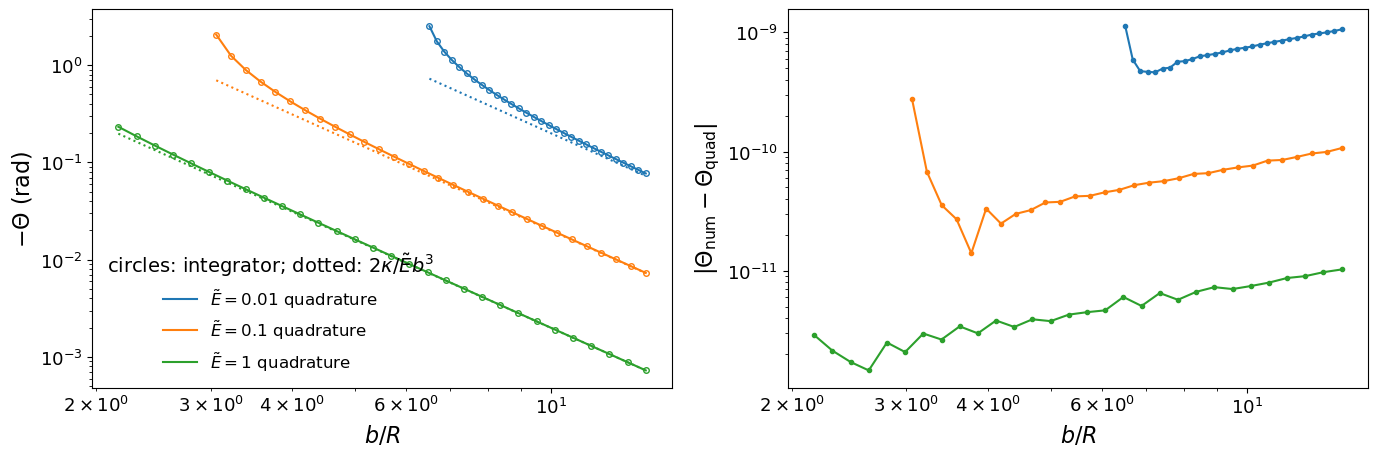

max |Theta_num - Theta_quad| = 1.1e-09 rad over 90 points (budget 1e-8)


In [6]:
fig, (ax, ax_err) = plt.subplots(1, 2, figsize=(14, 4.8))
worst = 0.0
for k, energy in enumerate([0.01, 0.1, 1.0]):
    b_c = central.capture_impact_parameter(energy, 1.0)
    bs = np.geomspace(1.02 * b_c, 14.0, 30)
    numeric = np.array([run_trajectory(energy, b, Z, -Z, method=FAST)["deflection"] for b in bs])
    quad = np.array([central.deflection_angle(energy, b, 1.0) for b in bs])
    worst = max(worst, np.max(np.abs(numeric - quad)))
    ax.plot(bs, -quad, "-", color=f"C{k}", label=fr"$\tilde{{E}}={energy:g}$ quadrature")
    ax.plot(bs, -numeric, "o", color=f"C{k}", ms=4, mfc="none")
    ax.plot(bs, -central.small_angle_deflection(energy, bs, 1.0), ":", color=f"C{k}")
    ax_err.semilogy(bs, np.abs(numeric - quad) + 1e-16, "o-", color=f"C{k}", ms=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$b/R$"); ax.set_ylabel(r"$-\Theta$ (rad)")
ax.legend(title="circles: integrator; dotted: $2\\kappa/\\tilde{E} b^3$")
ax_err.set_xscale("log"); ax_err.set_xlabel(r"$b/R$"); ax_err.set_ylabel(r"$|\Theta_{\rm num}-\Theta_{\rm quad}|$")
fig.tight_layout(); plt.show()
print(f"max |Theta_num - Theta_quad| = {worst:.1e} rad over 90 points (budget 1e-8)")

### 3b. Capture edge $b_c(\tilde{E})$ in both regimes

The edge is found by bisection on the outcome (`physics/capture.py`) and compared with the
two analytic branches, which meet at $\tilde{E}=\kappa/16$ with $\tilde{b}_c=2\sqrt3$. Near the
contact-limited edge the grazing dip below $r=2$ can fall inside a single integration step;
it is caught by checking every periapsis.

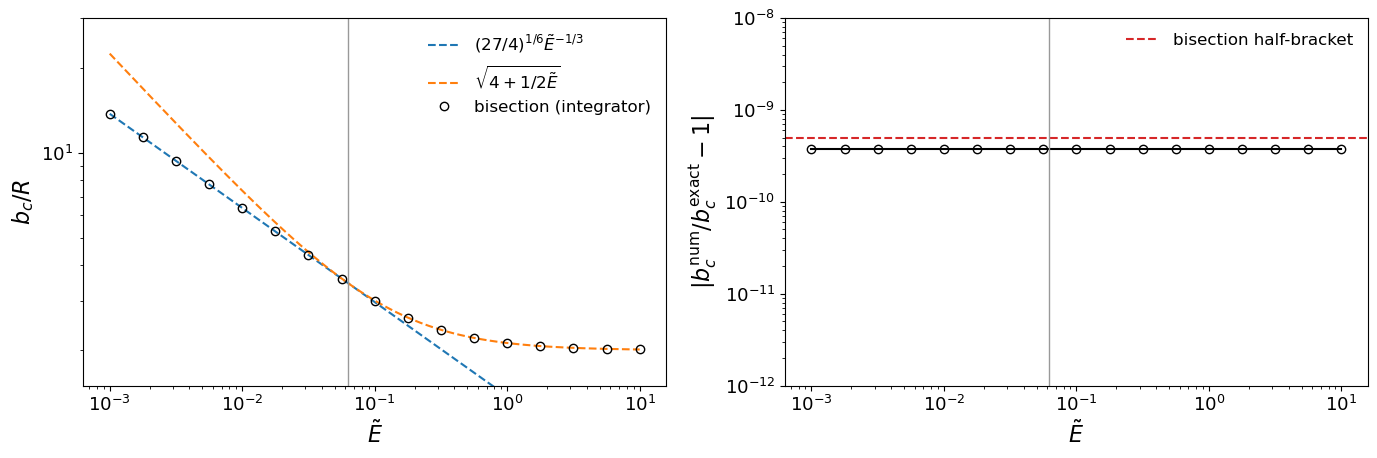

max relative error 3.7e-10 (bisection bracket 1e-9); crossover at E = 0.0625


In [7]:
energies = np.geomspace(1e-3, 10.0, 17)
found = np.array([find_capture_edge(e, Z, -Z, 0.9 * central.capture_impact_parameter(e, 1.0),
                                    1.1 * central.capture_impact_parameter(e, 1.0),
                                    rel_tol=1e-9, method=FAST)["edge"] for e in energies])
analytic = np.array([central.capture_impact_parameter(e, 1.0) for e in energies])

fig, (ax, ax_err) = plt.subplots(1, 2, figsize=(14, 4.8))
fine = np.geomspace(1e-3, 10.0, 400)
e_star = central.crossover_energy(1.0)
ax.loglog(fine, (27 / 4) ** (1 / 6) * fine ** (-1 / 3), "C0--", label=r"$(27/4)^{1/6}\tilde{E}^{-1/3}$")
ax.loglog(fine, np.sqrt(4 + 1 / (2 * fine)), "C1--", label=r"$\sqrt{4+1/2\tilde{E}}$")
ax.loglog(energies, found, "ko", mfc="none", label="bisection (integrator)")
ax.axvline(e_star, color="0.6", lw=1)
ax.set_xlabel(r"$\tilde{E}$"); ax.set_ylabel(r"$b_c/R$"); ax.set_ylim(1.5, 30); ax.legend()
ax_err.loglog(energies, np.abs(found / analytic - 1), "ko-", mfc="none")
ax_err.axhline(5e-10, color="C3", ls="--", label="bisection half-bracket")
ax_err.set_ylim(1e-12, 1e-8); ax_err.legend()
ax_err.axvline(e_star, color="0.6", lw=1)
ax_err.set_xlabel(r"$\tilde{E}$"); ax_err.set_ylabel(r"$|b_c^{\rm num}/b_c^{\rm exact}-1|$")
fig.tight_layout(); plt.show()
print(f"max relative error {np.max(np.abs(found / analytic - 1)):.1e} (bisection bracket 1e-9); "
      f"crossover at E = {e_star:g}")

### 3c. Orbiting near the barrier

Just outside a barrier-limited edge the particle circles near $r^*$ before escaping, and
$\Theta$ diverges logarithmically. The coefficient is the ratio of the angular speed at the
barrier to the barrier's instability rate, $\dot{\theta}(r^*)/\lambda$, which for $1/r^3$ is
exactly 1:
$$\Theta\simeq\ln(b-b_c)+\text{const}.$$

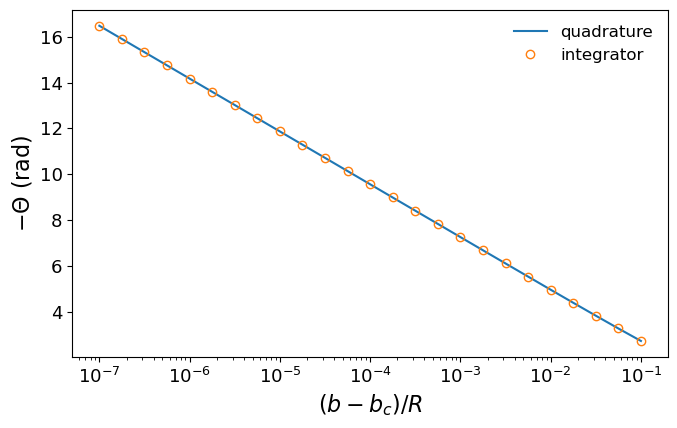

fitted slope dTheta/dln(b - b_c) = 0.9999 (derived value 1); the curve spans 2.6 full turns


In [8]:
energy = 0.01
b_c = central.capture_impact_parameter(energy, 1.0)
offsets = np.geomspace(1e-7, 1e-1, 25)
numeric = np.array([run_trajectory(energy, b_c + d, Z, -Z, method=FAST)["deflection"] for d in offsets])
quad = np.array([central.deflection_angle(energy, b_c + d, 1.0) for d in offsets])
slope = np.polyfit(np.log(offsets[:8]), numeric[:8], 1)[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(offsets, -quad, "-", label="quadrature")
ax.semilogx(offsets, -numeric, "o", mfc="none", label="integrator")
ax.set_xlabel(r"$(b-b_c)/R$"); ax.set_ylabel(r"$-\Theta$ (rad)"); ax.legend()
fig.tight_layout(); plt.show()
print(f"fitted slope dTheta/dln(b - b_c) = {slope:.4f} (derived value 1); "
      f"the curve spans {(-numeric).max() / (2 * np.pi):.1f} full turns")

### 3d. Convergence in the starting radius and the tolerance

After the in-state is matched to the energy and angular momentum at infinity, the only
start-radius error is the bending accumulated on the legs outside $r_0$, predicted to fall as
$r_0^{-4}$ (about $2\cdot3\kappa b/8\tilde{E} r_0^4$). The integration error sits below it at
rtol $=10^{-10}$.

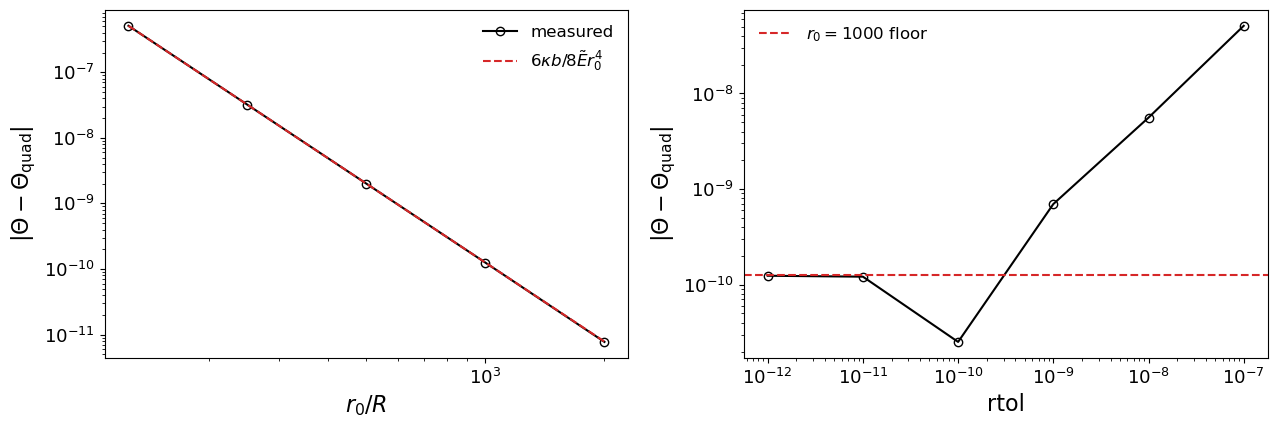

observed r0 orders: [4.   4.   4.   4.02]


In [9]:
energy, b = 0.03, 5.0
exact = central.deflection_angle(energy, b, 1.0)
r0s = np.array([125.0, 250.0, 500.0, 1000.0, 2000.0])
err_r0 = np.array([abs(run_trajectory(energy, b, Z, -Z, start_radius=r0, rtol=1e-13, atol=1e-15,
                                      method=FAST)["deflection"] - exact) for r0 in r0s])
rtols = np.array([1e-7, 1e-8, 1e-9, 1e-10, 1e-11, 1e-12])
err_rtol = np.array([abs(run_trajectory(energy, b, Z, -Z, rtol=rt, atol=rt * 1e-2,
                                        method=FAST)["deflection"] - exact) for rt in rtols])
orders = np.log2(err_r0[:-1] / err_r0[1:])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.loglog(r0s, err_r0, "ko-", mfc="none", label="measured")
ax1.loglog(r0s, 2 * 3 * b / (8 * energy * r0s**4), "C3--", label=r"$6\kappa b/8\tilde{E} r_0^4$")
ax1.set_xlabel(r"$r_0/R$"); ax1.set_ylabel(r"$|\Theta-\Theta_{\rm quad}|$"); ax1.legend()
ax2.loglog(rtols, err_rtol, "ko-", mfc="none")
ax2.axhline(err_r0[3], color="C3", ls="--", label=r"$r_0=1000$ floor")
ax2.set_xlabel("rtol"); ax2.set_ylabel(r"$|\Theta-\Theta_{\rm quad}|$"); ax2.legend()
fig.tight_layout(); plt.show()
print("observed r0 orders:", np.round(orders, 2))

## 4. Rotor dynamics (stage 4)

With the centers held fixed at separation $d$, the moment dynamics can be checked against the
second-order expansion of $U$ in the tilts:

- **Head-to-tail** ($\hat{\mu}_1=\hat{\mu}_2=\hat{r}$): $U\approx d^{-3}(-2+\alpha_1^2+\alpha_2^2+\alpha_1\alpha_2)$,
  normal modes $\omega^2=3/\tilde{I}d^3$ (in phase) and $1/\tilde{I}d^3$ (antiphase), each doubly degenerate.
- **$+z/-z$**, tilts toward $\hat{r}$: $U\approx d^{-3}(-1+\tfrac12\alpha^2+\tfrac12\beta^2-2\alpha\beta)$.
  The eigenvalue $-1$ belongs to the "scissor" mode $\alpha=\beta$, which is **unstable** with
  growth rate $\sigma=1/\sqrt{\tilde{I}d^3}$: started from rest, $\alpha(t)=\epsilon\cosh\sigma t$.

So the $+z/-z$ power-law case is an exact invariant manifold, but not a stable one.

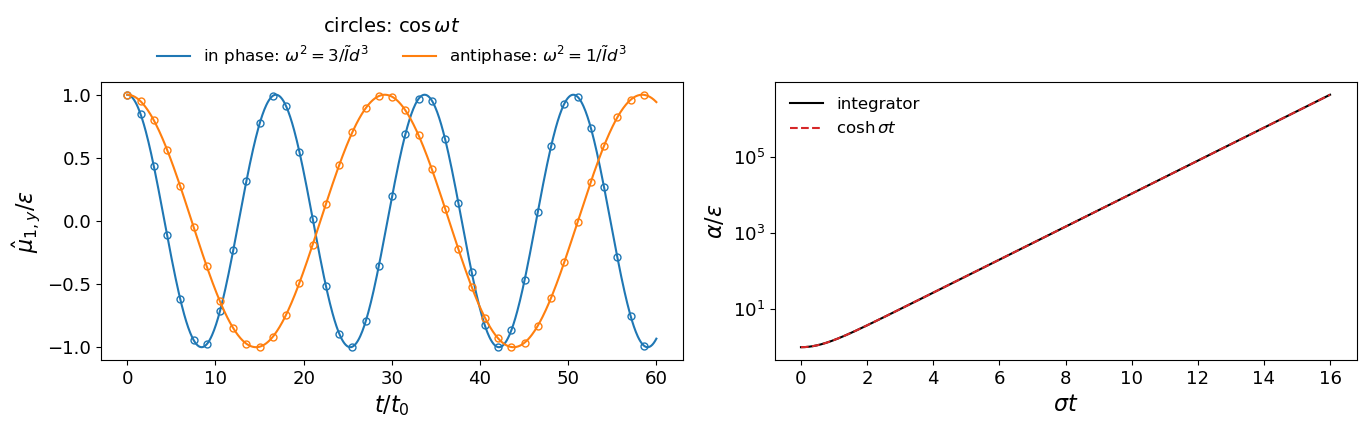

scissor growth: max |alpha/eps / cosh(sigma t) - 1| = 1.6e-08 over 16 e-folds


In [10]:
d = 3.0
def fixed_state(m1, m2):
    y = np.zeros(19)
    y[0:3] = (d, 0.0, 0.0)
    y[6:9] = np.asarray(m1, float) / np.linalg.norm(m1)
    y[9:12] = np.asarray(m2, float) / np.linalg.norm(m2)
    return y

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
eps = 1e-4
for sign, eig, color, label in [(+1, 3.0, "C0", "in phase"), (-1, 1.0, "C1", "antiphase")]:
    omega = np.sqrt(eig / (INERTIA * d**3))
    sol = integrate_state(fixed_state((1, eps, 0), (1, sign * eps, 0)), 60.0,
                          fixed_centers=True, rtol=1e-12, atol=1e-16, dense_output=True)
    t = np.linspace(0, sol.t[-1], 800)
    ax1.plot(t, sol.sol(t)[7] / eps, color=color, label=fr"{label}: $\omega^2={eig:g}/\tilde{{I}}d^3$")
    ax1.plot(t[::20], np.cos(omega * t[::20]), "o", color=color, mfc="none", ms=5)
ax1.set_xlabel(r"$t/t_0$"); ax1.set_ylabel(r"$\hat{\mu}_{1,y}/\epsilon$")
ax1.legend(title=r"circles: $\cos\omega t$", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)

sigma = 1 / np.sqrt(INERTIA * d**3)
eps = 1e-10
sol = integrate_state(fixed_state((np.sin(eps), 0, np.cos(eps)), (np.sin(eps), 0, -np.cos(eps))),
                      16 / sigma, fixed_centers=True, rtol=1e-12, atol=1e-20, dense_output=True)
t = np.linspace(0, 16 / sigma, 400)
tilt = np.arcsin(sol.sol(t)[6])
ax2.semilogy(sigma * t, tilt / eps, "k", label="integrator")
ax2.semilogy(sigma * t, np.cosh(sigma * t), "C3--", label=r"$\cosh\sigma t$")
ax2.set_xlabel(r"$\sigma t$"); ax2.set_ylabel(r"$\alpha/\epsilon$"); ax2.legend()
fig.tight_layout(); plt.show()
print(f"scissor growth: max |alpha/eps / cosh(sigma t) - 1| = {np.max(np.abs(tilt / eps / np.cosh(sigma * t) - 1)):.1e} "
      f"over {sigma * t[-1]:.0f} e-folds")

## 5. Conservation laws for generic 3D in-states (stage 4)

For generic moment directions the motion leaves the plane and the moments turn in 3D. Energy
and total angular momentum are conserved to the integration tolerance, while orbital angular
momentum is exchanged with spin. The cases are the seeded generic cases used by the tests.

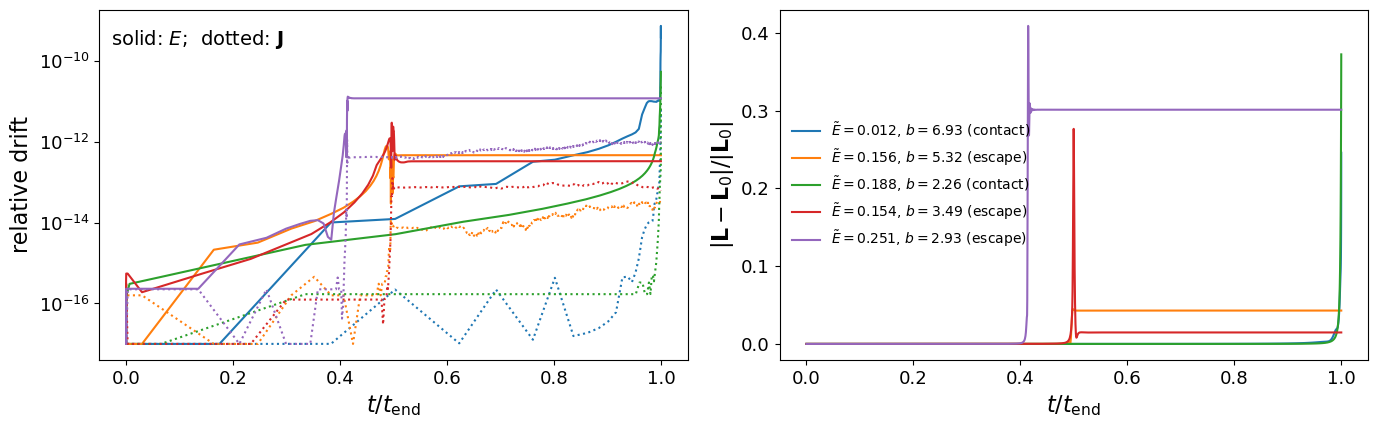

In [11]:
from tests.test_rotation import generic_cases

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for k, (energy, b, m1, m2) in enumerate(generic_cases()):
    res = run_trajectory(energy, b, m1, m2, keep_solution=True)
    sol = res["solution"]
    E = observables.total_energy(sol.y, INERTIA)
    J = observables.total_angular_momentum(sol.y, INERTIA)
    L = observables.orbital_angular_momentum(sol.y)
    t = sol.t / sol.t[-1]
    ax1.semilogy(t, np.abs(E - E[0]) / abs(E[0]) + 1e-17, color=f"C{k}")
    ax1.semilogy(t, np.linalg.norm(J - J[:, :1], axis=0) / np.linalg.norm(J[:, 0]) + 1e-17, ":", color=f"C{k}")
    ax2.plot(t, np.linalg.norm(L - L[:, :1], axis=0) / np.linalg.norm(L[:, 0]), color=f"C{k}",
             label=fr"$\tilde{{E}}={energy:.3f}$, $b={b:.2f}$ ({res['outcome']})")
ax1.set_xlabel(r"$t/t_{\rm end}$"); ax1.set_ylabel("relative drift")
ax1.text(0.02, 0.9, r"solid: $E$;  dotted: $\mathbf{J}$", transform=ax1.transAxes)
ax2.set_xlabel(r"$t/t_{\rm end}$"); ax2.set_ylabel(r"$|\mathbf{L}-\mathbf{L}_0|/|\mathbf{L}_0|$"); ax2.legend(fontsize=10)
fig.tight_layout(); plt.show()

## 6. The asymptotic in-state (stage 5)

A non-spinning moment approaching from infinity is already being turned by the torque, which
generically falls only as $1/r^3$. A moment direction specified at a finite $r_0$ therefore
differs from the one at $t\to-\infty$ by $O(1/\tilde{I}\tilde{E}r_0)$, and every observable
converges only linearly in $r_0$. The in-state adds the first-order rotation and spin picked
up on the straight incoming leg:

$$
\boldsymbol\omega_i(r_0)=\frac{1}{\tilde{I}v}\int_0^\infty\boldsymbol\tau_i\,ds,
\qquad
\delta\boldsymbol\theta_i(r_0)=\frac{1}{\tilde{I}v^2}\int_0^\infty s\,\boldsymbol\tau_i\,ds ,
$$

which should raise the convergence order from 1 to 2. The residual is
$\sim(1/\tilde{I}\tilde{E}r_0)^2$, so at the paper energy the orientation maps use $r_0=64000$.

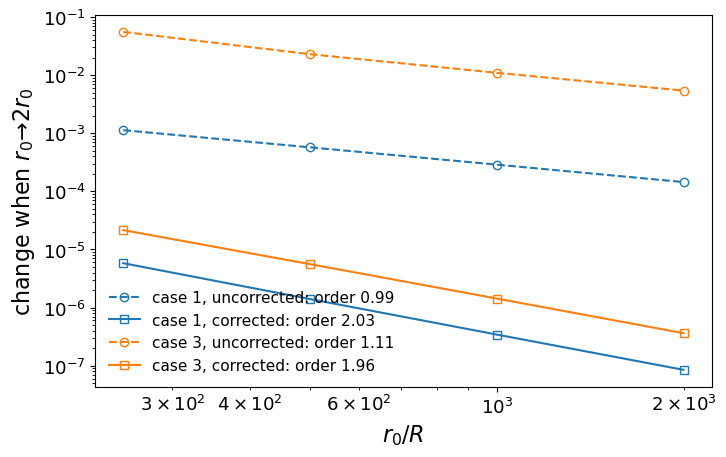

In [12]:
from tests.test_paper_comparison import generic_case

fig, ax = plt.subplots(figsize=(7.5, 4.8))
r0s = np.array([250.0, 500.0, 1000.0, 2000.0, 4000.0])
for index, color in [(1, "C0"), (3, "C1")]:
    energy, b, m1, m2 = generic_case(index)
    for correction, style in [(False, "o--"), (True, "s-")]:
        values = [np.concatenate([[r["deflection_3d"]], r["y_end"][12:18]])
                  for r in (run_trajectory(energy, b, m1, m2, start_radius=r0, outgoing_radius=8000.0,
                                           rtol=1e-12, atol=1e-14, asymptotic_correction=correction,
                                           method=FAST) for r0 in r0s)]
        diffs = np.linalg.norm(np.diff(np.array(values), axis=0), axis=1)
        order = np.polyfit(np.log(r0s[:-1]), np.log(diffs), 1)[0]
        ax.loglog(r0s[:-1], diffs, style, color=color, mfc="none",
                  label=f"case {index}, {'corrected' if correction else 'uncorrected'}: order {-order:.2f}")
ax.set_xlabel(r"$r_0/R$"); ax.set_ylabel(r"change when $r_0\to2r_0$"); ax.legend(fontsize=11)
fig.tight_layout(); plt.show()

## 7. The reference-paper configuration (stage 5)

Bartz & Shaw (arXiv:2212.00876) start the moments head-to-tail along $\hat{r}$. Their
$\tilde{R}=6.94$ and $v_i=5.78\times10^{-3}$ per sphere give $\tilde{E}=3\tilde{R}^3v_i^2=0.0335$.
Below, the full free-rotor dynamics are compared with the locked head-to-tail power law
($\kappa=2$), which is only the adiabatic limit. The paper quotes a largest colliding
$b/R=4.65$; our converged collision edge is 24% larger. The likely causes are a factor-2
convention difference and the paper counting only runs that **stuck**. This item is closed, and
the discrepancy is recorded as a strict xfail in the tests.

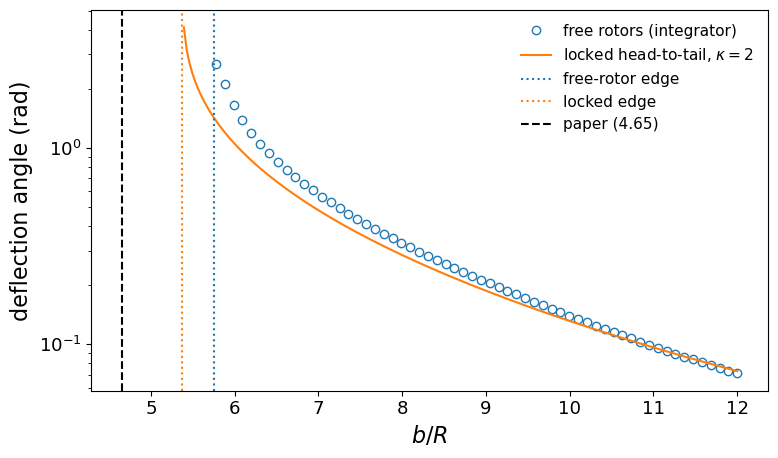

collision edge: free rotors 5.754590, locked 5.3729 (ratio 1.0710), paper 4.65


In [13]:
edge_full = find_capture_edge(E_PAPER, X_HAT, X_HAT, 5.70, 5.80, rel_tol=1e-10, method=FAST)["edge"]
edge_locked = central.capture_impact_parameter(E_PAPER, 2.0)
bs = np.linspace(edge_full + 0.02, 12.0, 60)
full = np.array([run_trajectory(E_PAPER, b, X_HAT, X_HAT, method=FAST)["deflection_3d"] for b in bs])
bs_locked = np.linspace(edge_locked + 0.02, 12.0, 200)
locked = -np.array([central.deflection_angle(E_PAPER, b, 2.0) for b in bs_locked])

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(bs, full, "o", mfc="none", label="free rotors (integrator)")
ax.plot(bs_locked, locked, "-", label=r"locked head-to-tail, $\kappa=2$")
for x, style, label in [(edge_full, "C0:", "free-rotor edge"), (edge_locked, "C1:", "locked edge"),
                        (TARGET_MAX_IMPACT_PARAMETER, "k--", "paper (4.65)")]:
    ax.axvline(x, color=style[:2] if style[0] == "C" else "k", ls=style[2:] if style[0] == "C" else "--", label=label)
ax.set_yscale("log"); ax.set_xlabel(r"$b/R$"); ax.set_ylabel(r"deflection angle (rad)"); ax.legend(fontsize=11)
fig.tight_layout(); plt.show()
print(f"collision edge: free rotors {edge_full:.6f}, locked {edge_locked:.4f} "
      f"(ratio {edge_full / edge_locked:.4f}), paper {TARGET_MAX_IMPACT_PARAMETER}")

## 8. In-plane orientation map (stage 6b)

### The question

In both power-law cases of Section 3, the collision edge depends on the energy alone:
$b_c=5.373R$ for locked head-to-tail moments and $4.264R$ for $+z/-z$ at the paper energy.
Free magnets are different. Their moments turn and spin up as they approach, so whether a
given impact parameter ends in a collision depends on **how the moments point when the
spheres are still far apart**. This section asks:

> *At fixed energy ($\tilde E=0.0335$, the paper's value), how does the largest colliding impact
> parameter depend on the initial orientations of the two moments? And is the set of colliding
> impact parameters always a single interval $0<b<b_{\rm out}$?*

This first survey keeps both moments **in the scattering plane**, so each orientation is one
angle. That gives a two-parameter family $(\phi_1,\phi_2)$ that can be shown as a map. Tilting
the moments out of the plane (making the motion three-dimensional) is a later stage.

### Geometry of the in-state

In the center-of-mass frame, sphere 2 comes in from the left moving in $+x$ and sphere 1 from
the right moving in $-x$. Their lines of approach are separated by the impact parameter $b$.
Each moment lies in the $xy$ plane at angle $\phi_i$, measured **counterclockwise from $+x$**
(the direction of the relative velocity). The angles are specified at $t\to-\infty$ for
non-spinning magnets. Some reference orientations:

- **head-to-tail**, $\phi_1=\phi_2=0$: both moments along the line of approach, attracting; the
  paper's configuration;
- **head-to-head**, $(0,\pi)$: pointing at each other along the approach line, repelling;
- **side-by-side**, $\phi=\pm\pi/2$: moments perpendicular to the approach. Parallel,
  $(\pi/2,\pi/2)$, repel on the approach axis; antiparallel, $(\pi/2,3\pi/2)$, attract.

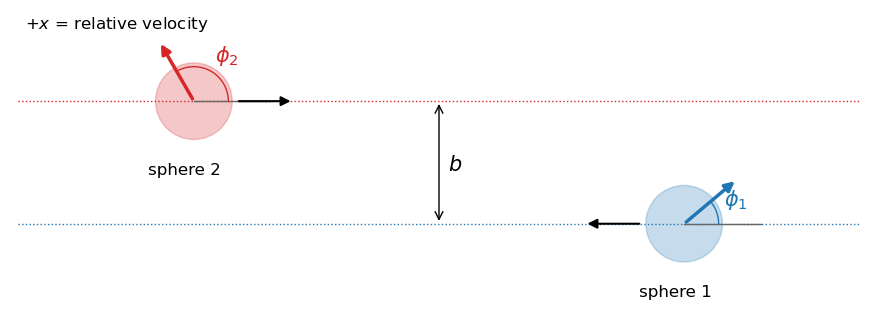

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.2))
b_demo, x_demo = 1.6, 3.2
phi1_demo, phi2_demo = np.radians(40), np.radians(120)
for x, y, vx, phi, color, name in [(+x_demo, -b_demo / 2, -1, phi1_demo, "C0", "1"),
                                   (-x_demo, +b_demo / 2, +1, phi2_demo, "C3", "2")]:
    ax.add_patch(plt.Circle((x, y), 0.5, color=color, alpha=0.25))
    ax.plot([-5.5, 5.5], [y, y], color=color, ls=":", lw=1)
    ax.annotate("", xy=(x + 1.3 * vx, y), xytext=(x + 0.55 * vx, y),
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))                 # velocity
    ax.annotate("", xy=(x + 0.9 * np.cos(phi), y + 0.9 * np.sin(phi)), xytext=(x, y),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))              # moment
    ax.plot([x, x + 1.0], [y, y], color="0.4", lw=1)                                   # +x reference
    arc = np.linspace(0, phi, 40)
    ax.plot(x + 0.45 * np.cos(arc), y + 0.45 * np.sin(arc), color=color, lw=1)
    ax.text(x + 0.55 * np.cos(phi / 2), y + 0.55 * np.sin(phi / 2) + 0.05, fr"$\phi_{name}$",
            color=color, fontsize=15)
    ax.text(x - 0.12, y - 0.95, f"sphere {name}", fontsize=12, ha="center")
ax.annotate("", xy=(0, b_demo / 2), xytext=(0, -b_demo / 2),
            arrowprops=dict(arrowstyle="<->", color="k", lw=1))
ax.text(0.12, -0.1, r"$b$", fontsize=15)
ax.text(-5.4, 1.75, r"$+x$ = relative velocity", fontsize=12)
ax.set_xlim(-5.6, 5.6); ax.set_ylim(-1.9, 2.0); ax.set_aspect("equal"); ax.axis("off")
fig.tight_layout(); plt.show()

### What is computed at each orientation

For one pair $(\phi_1,\phi_2)$, `physics.edges.capture_profile` runs full trajectories (the
same `run_trajectory` as everywhere else) on a grid of 200 impact parameters in
$0.05\le b/R\le10$ and records each outcome: **contact** or **escape**. Each change of outcome
between neighboring grid points is then located by bisection to relative width $10^{-6}$.
The result is the set of colliding impact parameters, summarized by three numbers:

- **outer collision edge $b_{\rm out}$**: the largest colliding $b$ (the map in the left panel
  below). In the power-law limits it is $b_c(\tilde E)$;
- **capture measure**: the total length of colliding $b$, which equals $b_{\rm out}-0.05$ when
  the set is a single interval;
- **number of contact intervals** (right panel): 1 when every $b<b_{\rm out}$ collides; 2 when an
  **escape window** opens inside the collision region.

Negative $b$ needs no separate run. Reflecting the in-state through the $xz$ plane maps $b\to-b$.
A magnetic moment is an axial vector, so under this reflection its in-plane angle goes to
$\pi-\phi_i$ (a polar vector would go to $-\phi_i$). The dynamics are bilinear in the moments, so
the two choices differ only by the global flip $\phi_i\to\phi_i+\pi$, which is itself a symmetry, and
they give identical results: checked directly, runs at $-b$ reproduce those at $+b$ with either
mapping to 10 digits. The total planar "cross section" (a length, for this 2D beam) is therefore
$\sigma(\phi_1,\phi_2)=\text{measure}(\phi_1,\phi_2)+\text{measure}(\pi-\phi_1,\pi-\phi_2)$, which equals
$\text{measure}(\phi_1,\phi_2)+\text{measure}(-\phi_1,-\phi_2)$.

**Numerics.** The grid is $32\times32$, spacing $\pi/16=11.25^\circ$. The trajectories start at
$r_0=64000$, where the in-state error in the edges is $\le3\times10^{-7}$ (Section 6). The map
is symmetric under $(\phi_1,\phi_2)\to(\phi_1+\pi,\phi_2+\pi)$ (flipping both moments leaves $U$
unchanged) and $(\phi_1,\phi_2)\to(\phi_2,\phi_1)$ (exchanging the spheres), so a quarter of it
is independent. It was accepted after three checks:
- tighter numerics on 18 points (edges agree to $4.9\times10^{-7}$);
- a 4× finer $b$ scan on all 1024 points (identical interval counts);
- a recomputation with the compiled integrator (identical map).

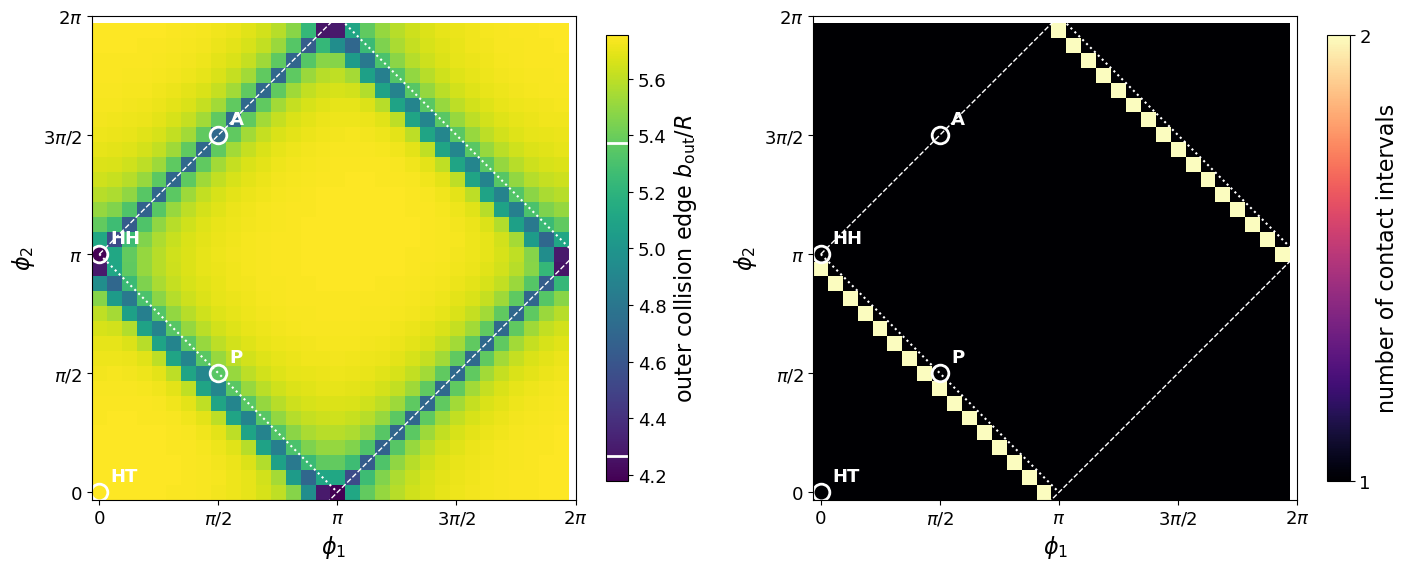

HT head-to-tail 5.755 | HH head-to-head 4.178 | P parallel side-by-side 5.353 | A antiparallel side-by-side 4.717
reference power laws: locked head-to-tail 5.373 (white line on the color bar), +z/-z 4.264
map mean 5.565; orientations with an escape window: 32 of 1024


In [15]:
ref = np.load(ROOT / "tests" / "reference" / "map_torus32.npz")
n = len(ref["phi"]); step = 2 * np.pi / n
extent = (-step / 2, 2 * np.pi - step / 2, -step / 2, 2 * np.pi - step / 2)
ticks = [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi]
labels = ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
named = {"HT": (0.0, 0.0), "HH": (0.0, np.pi), "P": (np.pi / 2, np.pi / 2), "A": (np.pi / 2, 3 * np.pi / 2)}

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
for ax, key, label, cmap in [(axes[0], "outer_edge", r"outer collision edge $b_{\rm out}/R$", "viridis"),
                             (axes[1], "n_intervals", "number of contact intervals", "magma")]:
    im = ax.imshow(ref[key].T, origin="lower", extent=extent, cmap=cmap, interpolation="nearest")
    cb = fig.colorbar(im, ax=ax, label=label, shrink=0.85)
    if key == "outer_edge":
        for value, text in [(central.capture_impact_parameter(E_PAPER, 2.0), "locked"),
                            (central.capture_impact_parameter(E_PAPER, 1.0), "+z/-z")]:
            if value > np.nanmin(ref[key]):
                cb.ax.axhline(value, color="w", lw=2)
    else:
        cb.set_ticks([1, 2])
    for name, (p1, p2) in named.items():
        ax.plot(p1, p2, "o", ms=12, mfc="none", mec="w", mew=2)
        ax.text(p1 + 0.15, p2 + 0.15, name, color="w", fontsize=13, fontweight="bold")
    ax.plot([0, 2 * np.pi], [np.pi, 3 * np.pi], "w--", lw=1); ax.plot([0, 2 * np.pi], [-np.pi, np.pi], "w--", lw=1)
    ax.plot([0, np.pi], [np.pi, 0], "w:", lw=1.5); ax.plot([np.pi, 2 * np.pi], [2 * np.pi, np.pi], "w:", lw=1.5)
    ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:])
    ax.set_xticks(ticks); ax.set_xticklabels(labels); ax.set_yticks(ticks); ax.set_yticklabels(labels)
    ax.set_xlabel(r"$\phi_1$"); ax.set_ylabel(r"$\phi_2$")
fig.tight_layout(); plt.show()

def edge(p1, p2):
    return ref["outer_edge"][int(round(p1 / step)) % n, int(round(p2 / step)) % n]
print("HT head-to-tail {:.3f} | HH head-to-head {:.3f} | P parallel side-by-side {:.3f} | "
      "A antiparallel side-by-side {:.3f}".format(*(edge(*named[k]) for k in ["HT", "HH", "P", "A"])))
print(f"reference power laws: locked head-to-tail {central.capture_impact_parameter(E_PAPER, 2.0):.3f} "
      f"(white line on the color bar), +z/-z {central.capture_impact_parameter(E_PAPER, 1.0):.3f}")
print(f"map mean {np.nanmean(ref['outer_edge']):.3f}; orientations with an escape window: "
      f"{int((ref['n_intervals'] == 2).sum())} of {n * n}")

### How to read the map

Each pixel is one pair of initial orientations; its color is the outer collision edge. White
circles mark the reference orientations above. The dashed lines are the **antiparallel**
orientations $\phi_2=\phi_1\pm\pi$, and the dotted lines are the **mirror** orientations
$\phi_1+\phi_2=\pi$ (and $3\pi$), where $\hat\mu_2$ is $\hat\mu_1$ reflected across the $y$ axis. The
pattern repeats under the two symmetries, so the four corners and the center tell the same
story.

**What the map shows.**
1. **A broad plateau.** Most orientations collide out to $b_{\rm out}\approx5.6$–$5.76$,
   *beyond* the locked head-to-tail value of 5.37. Rigidly locked, optimally aligned moments are
   therefore not the most "capturing" case; the free rotors do better. (The mechanism, spin–orbit
   exchange lowering the centrifugal barrier as in Section 2, is an interpretation still to be
   tested.)
2. **The minimum is head-to-head (HH).** Moments pointing at each other repel along the approach,
   and $b_{\rm out}$ drops to 4.18, below even the $+z/-z$ power law.
3. **A sharp, narrow dip along the antiparallel lines** (dashed): $b_{\rm out}\approx4.7$ on
   the line, but $\approx5.35$ one grid cell ($11^\circ$) away on either side. The line is special
   because, for $\hat\mu_2=-\hat\mu_1$, the two torques are **equal**, so non-spinning antiparallel
   moments turn together and stay antiparallel. Like $+z/-z$, the antiparallel orientations form
   an invariant family, and it behaves very differently from its neighbors. The dip is narrower
   than the grid spacing, so its true width and shape are not yet resolved.
4. **A lopsided trough just below the mirror line** (dotted). The edge falls steeply to 4.8–4.9
   at $\phi_1+\phi_2=15\pi/16$, recovers to 5.3 on the line itself, and rises slowly beyond it.
   The trough is also where every **escape window** sits (right panel): at those orientations,
   impact parameters $b\approx2.8$–$3.0$ escape even though smaller and larger $b$ collide.

The 1D cuts below make features 3 and 4 easier to see. Each is one row of the map read across a
line: on the left across the antiparallel line (a symmetric, one-cell-wide dip), on the right
across the mirror line (the trough sits one cell *below* the line). For $\phi_1=2\pi/16$, near HH,
the two lines run close together, so that cut crosses both features. That is the second dip in
each blue curve.

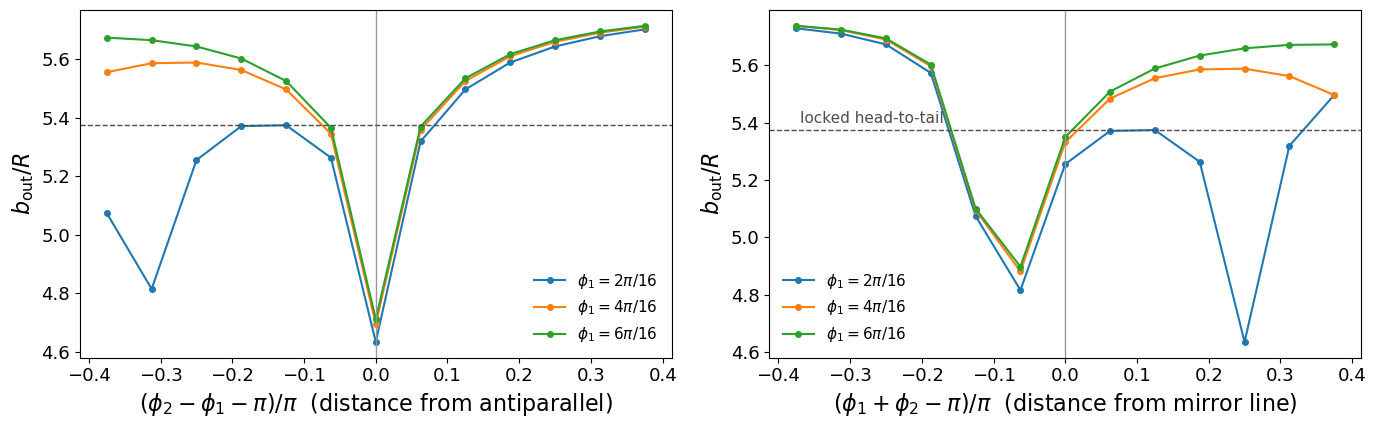

In [16]:
k = np.arange(-6, 7)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for i0, color in [(2, "C0"), (4, "C1"), (6, "C2")]:
    across_anti = [ref["outer_edge"][i0, (i0 + n // 2 + d) % n] for d in k]
    across_mirror = [ref["outer_edge"][i0, (n // 2 - i0 + d) % n] for d in k]
    ax1.plot(k * step / np.pi, across_anti, "o-", color=color, ms=4, label=fr"$\phi_1={i0}\pi/16$")
    ax2.plot(k * step / np.pi, across_mirror, "o-", color=color, ms=4, label=fr"$\phi_1={i0}\pi/16$")
for ax, xlabel in [(ax1, r"$(\phi_2-\phi_1-\pi)/\pi$  (distance from antiparallel)"),
                   (ax2, r"$(\phi_1+\phi_2-\pi)/\pi$  (distance from mirror line)")]:
    ax.axvline(0, color="0.6", lw=1)
    ax.axhline(central.capture_impact_parameter(E_PAPER, 2.0), color="0.3", ls="--", lw=1)
    ax.set_xlabel(xlabel); ax.set_ylabel(r"$b_{\rm out}/R$"); ax.legend(fontsize=11)
ax2.text(-0.37, 5.40, "locked head-to-tail", fontsize=11, color="0.3")
fig.tight_layout(); plt.show()

**One orientation in detail.** $(\phi_1,\phi_2)=(0,15\pi/16)$ sits in the trough, where an escape
window opens. The strip below is its profile, recomputed live with the compiled integrator at
the production settings. Each tick is one trajectory (red: contact, blue: escape), shading marks
the colliding intervals, and black lines are the bisected edges. The recomputation is repeated
with tighter numerics (rtol $10^{-12}$, $2r_0$, twice the scan points) to show that the window is
not a numerical artifact.

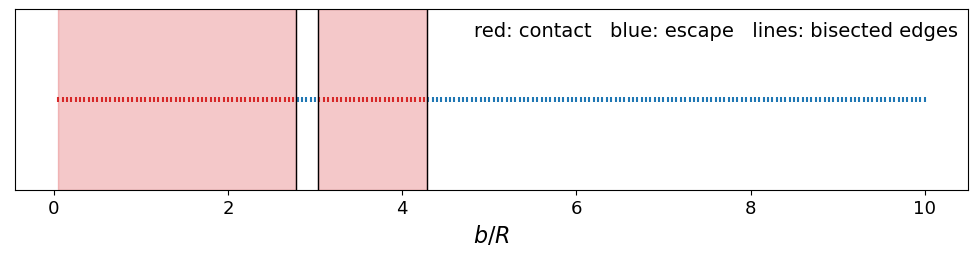

edges (production): [2.779617 3.03091  4.289113]
edges (tight):      [2.779617 3.030911 4.289112]
max relative difference 2.7e-07; stored map value of the outer edge 4.289113
escape window: 2.7796 < b/R < 3.0309


In [17]:
phi1, phi2 = 0.0, 2 * np.pi * 15 / 32
production = dict(start_radius=64000.0, method=FAST)
prof = in_plane_profile(E_PAPER, phi1, phi2, **production)
tight = in_plane_profile(E_PAPER, phi1, phi2, n_scan=400, rtol=1e-12, atol=1e-14,
                         start_radius=128000.0, method=FAST)

fig, ax = plt.subplots(figsize=(10, 2.8))
grid = np.linspace(0.05, 10.0, len(prof["scan_codes"]))
colors = {"c": "C3", "e": "C0", "t": "k"}
ax.scatter(grid, np.zeros_like(grid), c=[colors[c] for c in prof["scan_codes"]], s=12, marker="|")
for (lo, hi) in prof["intervals"]:
    ax.axvspan(lo, hi, color="C3", alpha=0.25)
for e in prof["edges"]:
    ax.axvline(e, color="k", lw=1)
ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel(r"$b/R$")
ax.text(0.99, 0.85, "red: contact   blue: escape   lines: bisected edges", transform=ax.transAxes, ha="right")
fig.tight_layout(); plt.show()
print("edges (production):", np.round(prof["edges"], 6))
print("edges (tight):     ", np.round(tight["edges"], 6))
print(f"max relative difference {np.max(np.abs(np.array(tight['edges']) / np.array(prof['edges']) - 1)):.1e}; "
      f"stored map value of the outer edge {ref['outer_edge'][0, 15]:.6f}")
print(f"escape window: {prof['edges'][0]:.4f} < b/R < {prof['edges'][1]:.4f}")

**What is established, and what is not.** The map values at the grid points are converged, and
the escape windows are real. Not yet known:
- the width and internal structure of the antiparallel dip and of the trough, which are narrower
  than the grid;
- whether the trough and the windows are tied to an instability of the antiparallel or mirror
  families, analogous to the $+z/-z$ scissor mode;
- whether the capture boundary has finer, possibly fractal, structure there.

These are the first next steps in Section 10.

### The same map on a $256\times256$ grid

With the compiled integrator (Section 9) the whole torus at 8× the resolution takes 5.4 minutes on
18 workers (65536 points, stored in `tests/reference/map_torus256.npz`). Every 8th point is a point of
the $32\times32$ map and reproduces it exactly. The antiparallel dip and the mirror trough, narrower
than the coarse grid, now show up as lines. The deepest point is on the antiparallel line near
tail-to-tail, where Section 10c zooms in further.

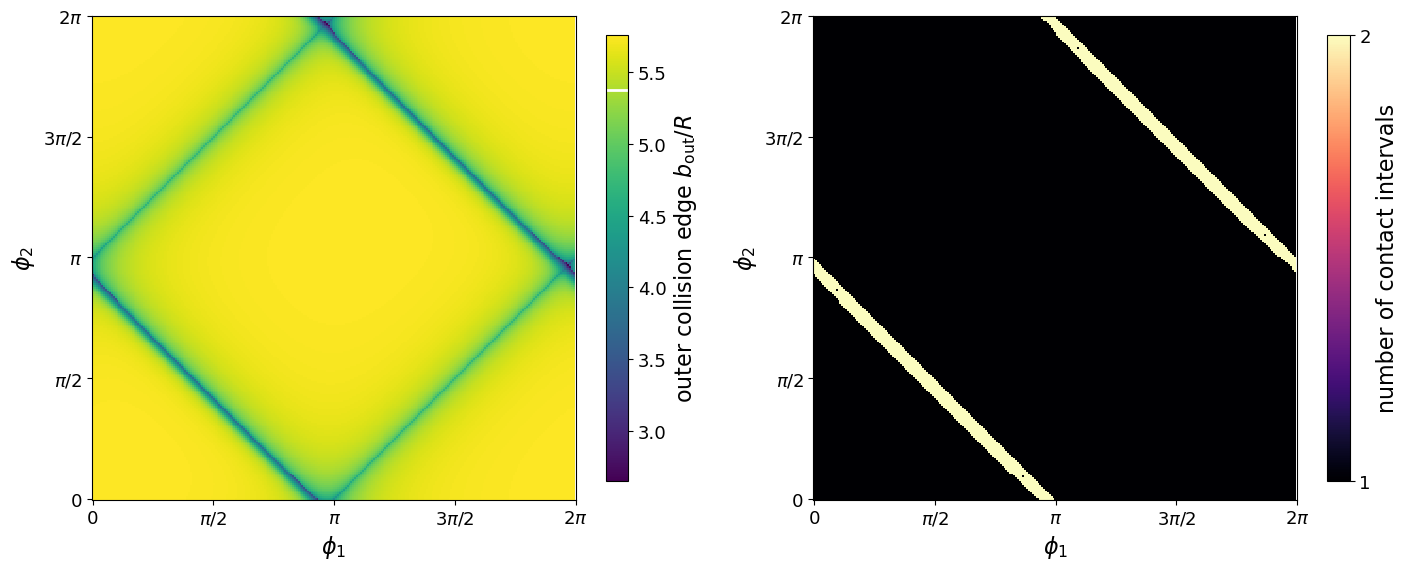

256 x 256 subgrid vs 32 x 32 map: max rel outer-edge difference 0.0e+00, interval counts identical: True
minimum b_out 2.656 at (phi1, phi2) = (0.969, 1.969) pi (coarse-map minimum 4.178); mean 5.564; escape windows at 2456 of 65536 orientations


In [ ]:
fine = np.load(ROOT / "tests" / "reference" / "map_torus256.npz")
nf = len(fine["phi"]); step_f = 2 * np.pi / nf
extent_f = (-step_f / 2, 2 * np.pi - step_f / 2, -step_f / 2, 2 * np.pi - step_f / 2)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
for ax, key, label, cmap in [(axes[0], "outer_edge", r"outer collision edge $b_{\rm out}/R$", "viridis"),
                             (axes[1], "n_intervals", "number of contact intervals", "magma")]:
    im = ax.imshow(fine[key].T, origin="lower", extent=extent_f, cmap=cmap, interpolation="nearest")
    cb = fig.colorbar(im, ax=ax, label=label, shrink=0.85)
    if key == "outer_edge":
        cb.ax.axhline(central.capture_impact_parameter(E_PAPER, 2.0), color="w", lw=2)
    else:
        cb.set_ticks([1, 2])
    ax.set_xticks(ticks); ax.set_xticklabels(labels); ax.set_yticks(ticks); ax.set_yticklabels(labels)
    ax.set_xlabel(r"$\phi_1$"); ax.set_ylabel(r"$\phi_2$")
fig.tight_layout(); plt.show()

sub = slice(None, None, nf // n)
print(f"{nf} x {nf} subgrid vs {n} x {n} map: max rel outer-edge difference "
      f"{np.nanmax(np.abs(fine['outer_edge'][sub, sub] - ref['outer_edge']) / ref['outer_edge']):.1e}, "
      f"interval counts identical: {np.array_equal(fine['n_intervals'][sub, sub], ref['n_intervals'])}")
i, j = np.unravel_index(np.nanargmin(fine["outer_edge"]), fine["outer_edge"].shape)
print(f"minimum b_out {fine['outer_edge'][i, j]:.3f} at (phi1, phi2) = ({i / (nf / 2):.3f}, {j / (nf / 2):.3f}) pi "
      f"(coarse-map minimum {np.nanmin(ref['outer_edge']):.3f}); mean {np.nanmean(fine['outer_edge']):.3f}; "
      f"escape windows at {int((fine['n_intervals'] == 2).sum())} of {nf * nf} orientations")

## 9. The compiled integrator (stage 7)

`physics/fast.py` is a Numba transcription of scipy's DOP853: the same tableau, error norm,
step control, dense output, Brent root-finding for events, and event ordering. The in-state
integral uses Gauss–Legendre quadrature instead of `quad_vec`. For identical inputs the two
paths take the same steps. The check below compares one generic trajectory computed both ways.

In [18]:
energy, b, m1, m2 = generic_cases()[1]
t0 = time.perf_counter(); ref_run = run_trajectory(energy, b, m1, m2); t_ref = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(20):
    fast_run = run_trajectory(energy, b, m1, m2, method=FAST)
t_fast = (time.perf_counter() - t0) / 20
print(f"RHS evaluations: scipy {ref_run['n_rhs']}, numba {fast_run['n_rhs']}  (same step sequence)")
print(f"end-state max difference {np.max(np.abs(ref_run['y_end'] - fast_run['y_end'])):.1e}; "
      f"outcome {ref_run['outcome']} / {fast_run['outcome']}")
print(f"time per trajectory: scipy {t_ref * 1e3:.1f} ms, numba {t_fast * 1e3:.2f} ms  "
      f"-> {t_ref / t_fast:.0f}x faster")

RHS evaluations: scipy 6335, numba 6335  (same step sequence)
end-state max difference 3.3e-13; outcome escape / escape
time per trajectory: scipy 559.5 ms, numba 1.10 ms  -> 509x faster


## 10. Zoomed maps and the fine structure of the capture boundary (stage 8)

The $32\times32$ map (Section 8) left three features narrower than its $11.25^\circ$ grid:
- the dip along the antiparallel lines;
- the band of escape windows next to the mirror line;
- the low-edge corner near head-to-head / tail-to-tail.

Stage 8 zooms in on each of them with grids up to 512 times finer. It then asks whether the
capture boundary inside the window band is smooth or fractal.

**Grids.** Strips are laid out in coordinates along ($s$) and across ($d$) a line of the torus:
- **antiparallel:** $\phi_1=s$, $\phi_2=s+\pi+d$, so $d=0$ is $\hat\mu_2=-\hat\mu_1$;
- **mirror:** $\phi_1=s$, $\phi_2=\pi-s+d$, so $d=0$ is $\hat\mu_2$ reflected across the $y$ axis.

The step across is $\pi/512$ ($0.35^\circ$) and the step along is $\pi/64$. Two plain patches in
$(\phi_1,\phi_2)$ cover the tail-to-tail corner at $(\pi,0)$, which the global flip makes
equivalent to head-to-head: one at $\pi/512$, and a finer one at $\pi/8192$ ($0.022^\circ$). All
use the paper energy, $r_0=64000$ and the compiled integrator. The grids were chosen so that some
strip points coincide with torus-map points; those reproduce the stored map (tests).

**Acceptance.** Every zoomed map was computed twice, with 200 and with 800 scan points in $b$.
- **The outer collision edge converges** on both strips and on the coarse patch: the two scans
  agree to $\le9.3\times10^{-7}$.
- **The interval structure does not converge** inside the window band. The finer scan uncovers
  thin escape windows, and at even finer scans sub-windows, that the coarser one steps over.

Interval counts and capture measures are therefore lower bounds there. Section 10d measures what
kind of set the boundary is.

The cell below loads the stored results (`tests/reference/zoom_maps.npz`, written from committed
code) and re-checks a few points live against them.

In [19]:
from physics.edges import strip_angles, capture_profile
import json

zoom = np.load(ROOT / "tests" / "reference" / "zoom_maps.npz")
def zoom_map(key):
    meta = json.loads(str(zoom[f"{key}__meta"]))
    return {"b_out": zoom[f"{key}__outer_edge"], "n_int": zoom[f"{key}__n_intervals"],
            "along": zoom[f"{key}__along"], "across": zoom[f"{key}__across"], **meta}

maps = {k: zoom_map(k) for k in ["strip_anti", "strip_mirror", "patch_tt", "patch_min"]}
for k, m in maps.items():
    print(f"{k:13s} {m['b_out'].shape[0]:3d} x {m['b_out'].shape[1]:3d} points, step "
          f"{np.degrees(m['across'][1] - m['across'][0]):.3f} deg across; code {m['git_hash'][:8]}")

# Live re-check of a few stored points, each at its own map's recorded settings (800 scan points).
worst = 0.0
for key, i, j in [("strip_anti", 16, 40), ("strip_anti", 40, 60), ("strip_mirror", 16, 20), ("strip_mirror", 48, 130)]:
    m = maps[key]
    settings = m["settings"]
    p1, p2 = strip_angles(m["grid"]["line"], m["along"][i], m["across"][j])
    prof = capture_profile(E_PAPER, moment_direction(p1), moment_direction(p2), b_min=settings["b_min"],
                           b_max=settings["b_max"], n_scan=settings["n_scan"], rel_tol=settings["rel_tol"],
                           start_radius=settings["start_radius"], method=FAST)
    worst = max(worst, abs(prof["outer_edge"] / m["b_out"][i, j] - 1))
print(f"live re-check of 4 stored strip points: max relative difference in b_out {worst:.1e}")

strip_anti     64 x  81 points, step 0.352 deg across; code 088c16f3
strip_mirror   64 x 145 points, step 0.352 deg across; code 088c16f3
patch_tt       97 x  97 points, step 0.352 deg across; code 9c9cc411
patch_min      65 x  65 points, step 0.022 deg across; code 33f83b5b


live re-check of 4 stored strip points: max relative difference in b_out 0.0e+00


### 10a. The antiparallel dip is a smooth cusp

Across the antiparallel line the outer edge falls smoothly into a cusp. On the line it reaches
$b_{\rm out}\approx4.6$–$4.72$ for $0.1\pi<s<0.9\pi$, dropping toward 4.18 as $s$ approaches
head-to-head ($s\to0$) or tail-to-tail ($s\to\pi$), where the line meets the window band. The
cusp's shape is the same at every $s$. The coarse map's "sharp dip" was this cusp, sampled once on the line and once
$11^\circ$ away. The line is special because the two torques are equal when
$\hat\mu_2=-\hat\mu_1$: non-spinning antiparallel moments turn together and stay antiparallel,
which makes them an invariant family (checked to machine precision).

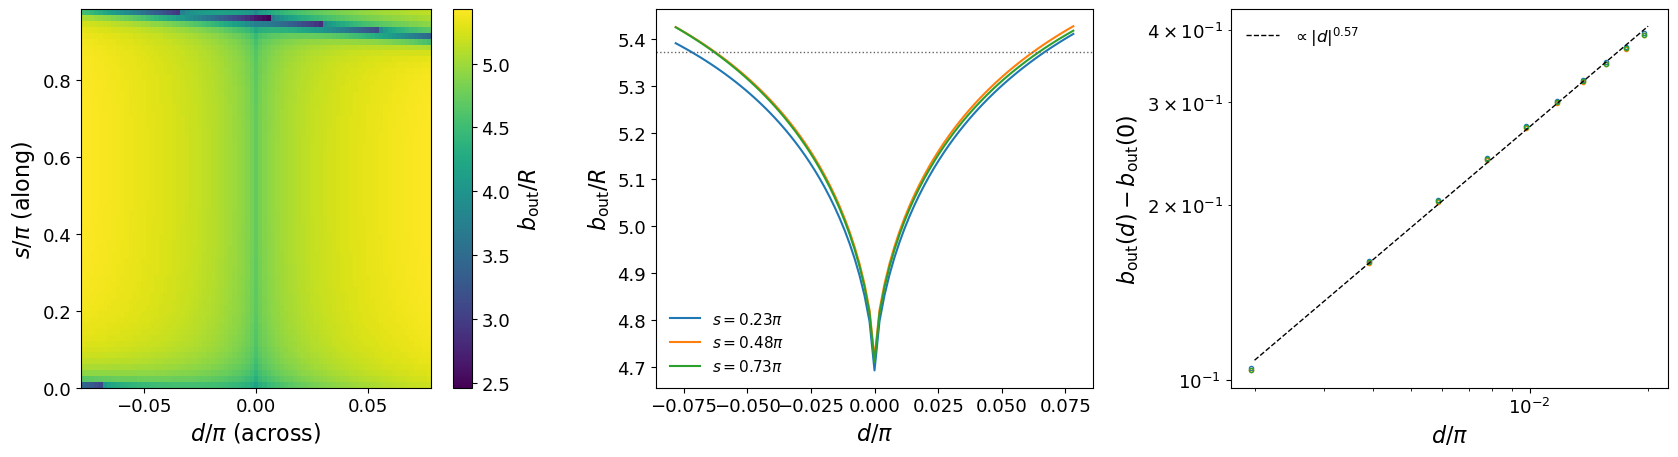

on the line b_out = 4.615 .. 4.718 for 0.1 pi < s < 0.9 pi (2.656 at the ends); full width at half depth 0.0312 pi = 5.6 deg; cusp exponent 0.57


In [20]:
m = maps["strip_anti"]
d = m["across"]; j0 = int(np.argmin(np.abs(d)))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
ext = (d[0] / np.pi, d[-1] / np.pi, m["along"][0] / np.pi, m["along"][-1] / np.pi)
im = ax1.imshow(m["b_out"], origin="lower", extent=ext, aspect="auto", cmap="viridis", interpolation="nearest")
fig.colorbar(im, ax=ax1, label=r"$b_{\rm out}/R$")
ax1.set_xlabel(r"$d/\pi$ (across)"); ax1.set_ylabel(r"$s/\pi$ (along)")
widths, powers = [], []
for k in (15, 31, 47):
    row = m["b_out"][k]
    ax2.plot(d / np.pi, row, lw=1.5, label=fr"$s={m['along'][k] / np.pi:.2f}\pi$")
    depth = 0.5 * (row[0] + row[-1]) - row[j0]
    inside = row < row[j0] + 0.5 * depth
    widths.append(d[inside].max() - d[inside].min())
    pos = (d > 0) & (d < 0.02 * np.pi)
    powers.append(np.polyfit(np.log(d[pos]), np.log(row[pos] - row[j0]), 1)[0])
    ax3.loglog(d[pos] / np.pi, row[pos] - row[j0], "o", ms=3, mfc="none")
ax2.axhline(central.capture_impact_parameter(E_PAPER, 2.0), color="0.4", ls=":", lw=1)
ax2.set_xlabel(r"$d/\pi$"); ax2.set_ylabel(r"$b_{\rm out}/R$"); ax2.legend(fontsize=11)
dd = np.geomspace(2e-3, 2e-2, 10)
row = m["b_out"][31]; pos = (d > 0) & (d < 0.02 * np.pi)
amp = np.median((row[pos] - row[j0]) / (d[pos] / np.pi) ** np.mean(powers))
ax3.loglog(dd, amp * dd**np.mean(powers), "k--", lw=1, label=fr"$\propto|d|^{{{np.mean(powers):.2f}}}$")
ax3.set_xlabel(r"$d/\pi$"); ax3.set_ylabel(r"$b_{\rm out}(d)-b_{\rm out}(0)$"); ax3.legend()
fig.tight_layout(); plt.show()
mid = (m["along"] > 0.1 * np.pi) & (m["along"] < 0.9 * np.pi)
print(f"on the line b_out = {m['b_out'][mid, j0].min():.3f} .. {m['b_out'][mid, j0].max():.3f} for 0.1 pi < s < 0.9 pi "
      f"({m['b_out'][:, j0].min():.3f} at the ends); full width at half depth "
      f"{np.mean(widths) / np.pi:.4f} pi = {np.degrees(np.mean(widths)):.1f} deg; cusp exponent {np.mean(powers):.2f}")

### 10b. The mirror "trough" is a band of escape windows

On the mirror strip, the escape windows fill a band about $0.075\pi$ ($13.5^\circ$) wide just below
the mirror line ($-0.075\pi\lesssim d\lesssim0$). On the band's lower side the outer edge jumps
sharply. The coarse map sampled this band at a single row of points ($d=-\pi/16$), which is why it
looked like a narrow trough. Inside the band, the window sits at an impact parameter that moves
smoothly with $d$, from $b\approx2.8$ near $d=-0.06\pi$ down to $b\approx0.4$ close to the line.
The interval-count panel below is a **lower bound** (Section 10d).

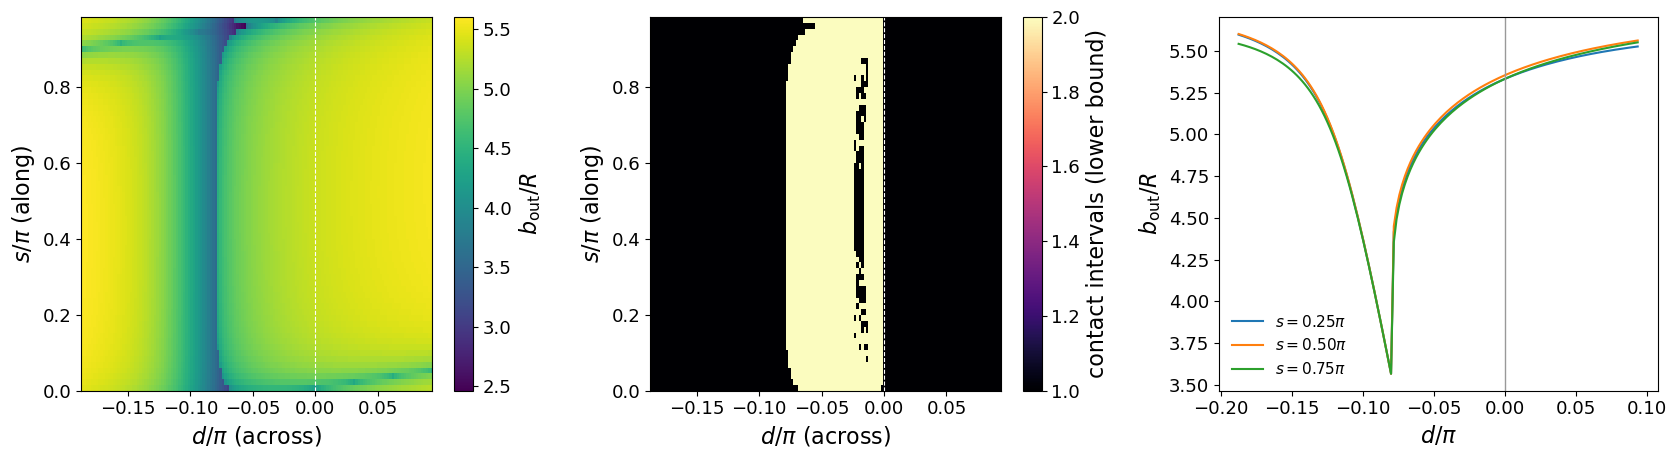

escape windows at 25% of strip points; band spans d/pi = -0.078 .. -0.002


In [21]:
m = maps["strip_mirror"]
d = m["across"]
ext = (d[0] / np.pi, d[-1] / np.pi, m["along"][0] / np.pi, m["along"][-1] / np.pi)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, key, label, cmap in [(axes[0], "b_out", r"$b_{\rm out}/R$", "viridis"), (axes[1], "n_int", "contact intervals (lower bound)", "magma")]:
    im = ax.imshow(m[key], origin="lower", extent=ext, aspect="auto", cmap=cmap, interpolation="nearest")
    fig.colorbar(im, ax=ax, label=label)
    ax.axvline(0, color="w", lw=0.8, ls="--")
    ax.set_xlabel(r"$d/\pi$ (across)"); ax.set_ylabel(r"$s/\pi$ (along)")
for k in (16, 32, 48):
    axes[2].plot(d / np.pi, m["b_out"][k], lw=1.5, label=fr"$s={m['along'][k] / np.pi:.2f}\pi$")
axes[2].axvline(0, color="0.6", lw=1)
axes[2].set_xlabel(r"$d/\pi$"); axes[2].set_ylabel(r"$b_{\rm out}/R$"); axes[2].legend(fontsize=11)
fig.tight_layout(); plt.show()
band = (m["n_int"] >= 2)
print(f"escape windows at {band.mean() * 100:.0f}% of strip points; band spans d/pi = "
      f"{d[band.any(axis=0)].min() / np.pi:.3f} .. {d[band.any(axis=0)].max() / np.pi:.3f}")

### 10c. The tail-to-tail corner

Near tail-to-tail $(\pi,0)$ the antiparallel line (slope $+1$ in the $(\phi_2,\phi_1)$ plane below)
and the mirror line (slope $-1$) cross. The window band runs along the mirror line, and the deepest
outer edge anywhere sits where the band's sharp lower boundary meets the antiparallel cusp. Exact
tail-to-tail itself is unremarkable ($b_{\rm out}=4.18$).

The finer patch ($0.022^\circ$ steps, centered on the coarse minimum) shows a low region,
$b_{\rm out}\approx2.2$–$2.5$. It is bounded by two sharp edges that meet at the antiparallel cusp,
and the deepest values ($2.13$) lie at that corner, on the cusp line. This is the lowest outer edge
found so far, well below the torus minimum of 4.18. The deepest pixel dropped as the resolution
improved, $2.46$ on the strip and $2.17$ on the coarse patch, and then held at $2.13$ on the fine
patch in both the off-center and the centered runs. In this crossing region the finer $b$ scan
also finds thin contact slivers just above $b_{\rm out}$ at 1.2% of the fine-patch points, so there
$b_{\rm out}$ is itself a lower bound.

patch_tt: min b_out 2.1688 at (phi1, phi2) = (0.97461, -0.02539) pi [step 0.352 deg]
patch_min: min b_out 2.1272 at (phi1, phi2) = (0.97510, -0.02490) pi [step 0.022 deg]


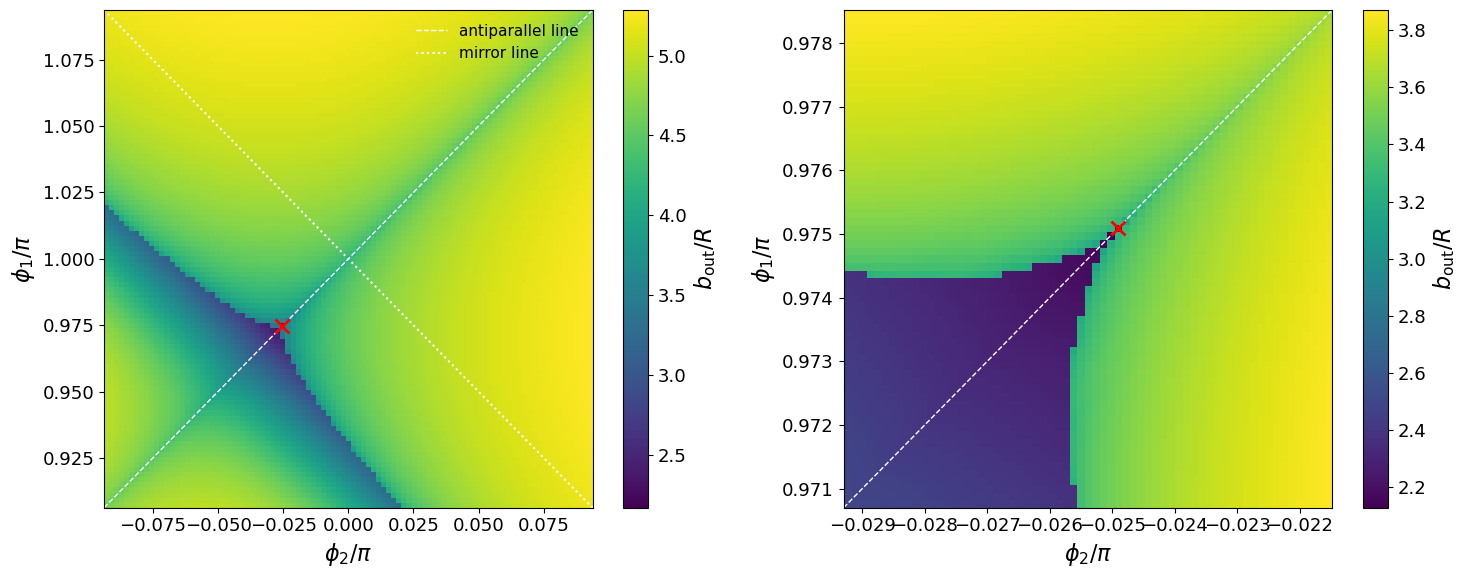

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, key in zip(axes, ["patch_tt", "patch_min"]):
    m = maps[key]
    p1, p2 = m["along"], m["across"]
    ext = (p2[0] / np.pi, p2[-1] / np.pi, p1[0] / np.pi, p1[-1] / np.pi)
    im = ax.imshow(m["b_out"], origin="lower", extent=ext, aspect="auto", cmap="viridis", interpolation="nearest")
    fig.colorbar(im, ax=ax, label=r"$b_{\rm out}/R$")
    x = np.linspace(p2[0], p2[-1], 50)
    ax.plot(x / np.pi, (x + np.pi) / np.pi, "w--", lw=1, label="antiparallel line")
    ax.plot(x / np.pi, (np.pi - x) / np.pi, "w:", lw=1.5, label="mirror line")
    i, j = np.unravel_index(np.nanargmin(m["b_out"]), m["b_out"].shape)
    ax.plot(p2[j] / np.pi, p1[i] / np.pi, "rx", ms=10, mew=2)
    ax.set_xlim(ext[:2]); ax.set_ylim(ext[2:])
    ax.set_xlabel(r"$\phi_2/\pi$"); ax.set_ylabel(r"$\phi_1/\pi$")
    print(f"{key}: min b_out {m['b_out'][i, j]:.4f} at (phi1, phi2) = ({p1[i] / np.pi:.5f}, {p2[j] / np.pi:+.5f}) pi "
          f"[step {np.degrees(p2[1] - p2[0]):.3f} deg]")
axes[0].legend(loc="upper right", fontsize=11)
fig.tight_layout(); plt.show()

### 10d. Is the boundary fractal? The uncertainty exponent

Draw impact parameters at random in an interval, and call $b$ *uncertain at scale $\epsilon$*
if the outcome at $b-\epsilon$, $b$ or $b+\epsilon$ differs. The uncertain fraction scales as
$$f(\epsilon)\propto\epsilon^{\alpha},\qquad D=1-\alpha,$$
where $D$ is the uncertainty dimension of the boundary (McDonald, Grebogi, Ott & Yorke 1985).
It is a local property of the sampled interval: over only the inner 64% of band B's interval,
where the structure is densest, an earlier run gave $\alpha=0.14$ instead of $0.27$.
- **Smooth edges:** $N$ of them give exactly $f=2N\epsilon/L$, so $\alpha=1$. The two
  **controls** have one edge each: the analytic $+z/-z$ edge, and an edge on the antiparallel
  line. They validate the method.
- **Fractal boundary:** $\alpha<1$. Refining the $b$ resolution then keeps uncovering edges, which
  is exactly the non-convergence seen in the refinement checks.

The study used 50,000 samples per point and $\epsilon$ from $L/30$ down to $10^{-6}$, where $L$ is
the interval length. That is well above the $\sim10^{-9}$ resolution of a single edge, and the
centers cover $\ge93\%$ of each interval. Recounting one band
point with rtol $10^{-12}$ or $r_0=128000$ gives Poisson-consistent fractions. Individual samples
closest to the boundary do change outcome (0.5–0.7% of them), as expected for a fractal set.

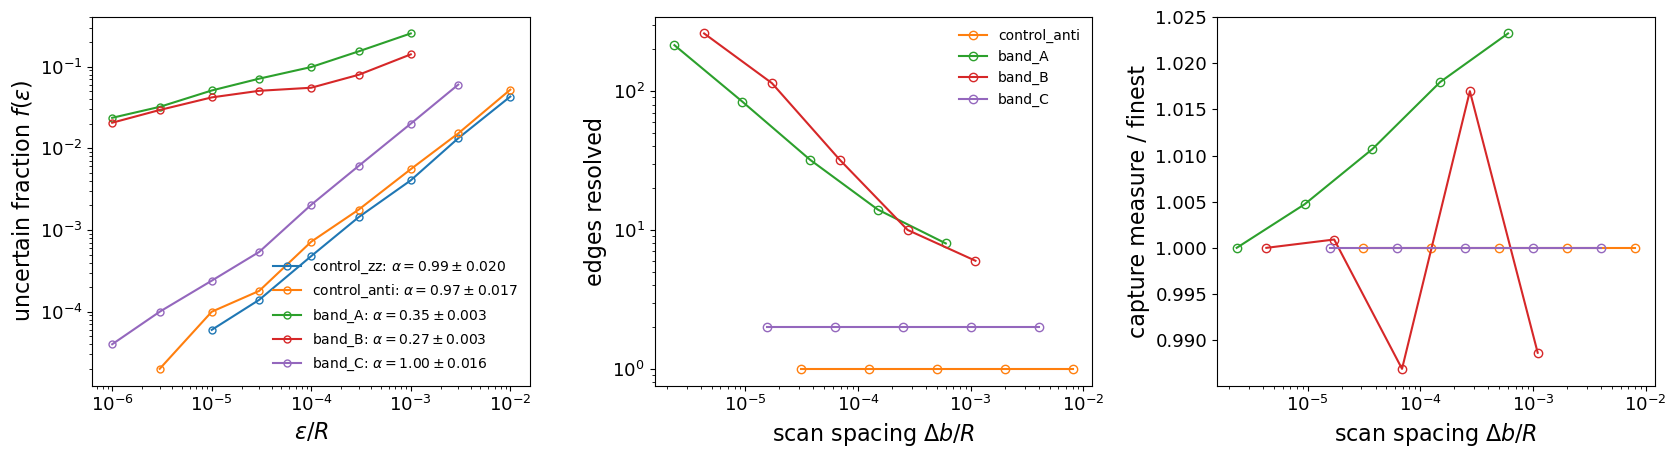

control_zz    +z/-z: one analytic edge at b_c              alpha = 0.990 +- 0.020  ->  D = 0.01
control_anti  antiparallel line s=pi/4: one smooth edge    alpha = 0.971 +- 0.017  ->  D = 0.03
band_A        mirror band s=pi/4, d=-0.03 pi               alpha = 0.351 +- 0.003  ->  D = 0.65
band_B        mirror band s=pi/2, d=-0.05 pi               alpha = 0.266 +- 0.003  ->  D = 0.73
band_C        mirror band s=pi/4, d=-0.07 pi               alpha = 0.998 +- 0.016  ->  D = 0.00
  numerics production : uncertain [1843, 933, 435] of 20000 (center outcomes changed: 0)
  numerics rtol 1e-12 : uncertain [1841, 934, 409] of 20000 (center outcomes changed: 91)
  numerics r0 128000  : uncertain [1855, 936, 439] of 20000 (center outcomes changed: 132)


live control: eps 1e-02: 157 uncertain vs 167 expected, eps 1e-03: 15 uncertain vs 17 expected


In [23]:
from physics.fractal import effective_length, fit_exponent, outcome_codes, sample_points, uncertain_counts

unc = json.loads((ROOT / "tests" / "reference" / "uncertainty_summary.json").read_text())
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
for k, (name, pt) in enumerate(unc["points"].items()):
    eps = np.array(pt["eps"]); f = np.array(pt["uncertain"]) / np.array(pt["totals"])
    ok = np.array(pt["uncertain"]) > 0
    ax1.loglog(eps[ok], f[ok], "o-", color=f"C{k}", mfc="none", ms=5,
               label=fr"{name}: $\alpha={pt['alpha']:.2f}\pm{pt['alpha_err']:.3f}$")
    if "resolution" in pt:
        db = [r["db"] for r in pt["resolution"]]
        ax2.loglog(db, [max(r["n_edges"], 0.8) for r in pt["resolution"]], "o-", color=f"C{k}", mfc="none", label=name)
        meas = np.array([r["capture_measure"] for r in pt["resolution"]])
        ax3.semilogx(db, meas / meas[-1], "o-", color=f"C{k}", mfc="none", label=name)
ax1.set_xlabel(r"$\epsilon/R$"); ax1.set_ylabel(r"uncertain fraction $f(\epsilon)$"); ax1.legend(fontsize=10)
ax2.set_xlabel(r"scan spacing $\Delta b/R$"); ax2.set_ylabel("edges resolved"); ax2.legend(fontsize=10)
ax3.set_xlabel(r"scan spacing $\Delta b/R$"); ax3.set_ylabel("capture measure / finest")
fig.tight_layout(); plt.show()
for name, pt in unc["points"].items():
    print(f"{name:13s} {pt['description']:44s} alpha = {pt['alpha']:.3f} +- {pt['alpha_err']:.3f}"
          f"  ->  D = {1 - pt['alpha']:.2f}")
if "numerics" in unc:
    for label, v in unc["numerics"]["variants"].items():
        print(f"  numerics {label:11s}: uncertain {v['uncertain']} of {v['totals'][0]} "
              f"(center outcomes changed: {v['center_outcomes_changed']})")

# Live mini-check of the method on the analytic control: f = 2 eps / L.
centers, eps, b_all = sample_points(4.0, 4.5, [1e-2, 1e-3], 4000, seed=3)
rows = uncertain_counts(outcome_codes(E_PAPER, Z, -Z, b_all, dict(start_radius=64000.0, method=FAST)), len(centers), eps)
L_eff = effective_length(4.0, 4.5, eps)
print("live control:", ", ".join(f"eps {e:.0e}: {c} uncertain vs {t * 2 * e / L_eff:.0f} expected"
                                for (c, t, _), e in zip(rows, eps)))

**What stage 8 establishes, and what it does not.**
- The antiparallel dip is resolved: a smooth, symmetric cusp,
  $b_{\rm out}(d)-b_{\rm out}(0)\propto|d|^{0.57}$, with a full width at half depth of $5.6^\circ$.
  Its width is *not* explained by the instability of the antiparallel family. An offset from exact
  antiparallel is amplified at most $\sim10^2$–$10^3$ times near the edge, which would give a dip
  about 100× narrower. What sets the $|d|^{0.57}$ shape is open.
- The window band is real and wide ($\sim13.5^\circ$). **Inside it the capture boundary is fractal:**
  $\alpha=0.35$ and $0.27$ at the two structured points ($D\approx0.65$ and $0.73$), against
  $\alpha\approx1$ for the controls and for a window with only two edges. The counts are robust to
  tighter numerics. The capture measure changes by only $\lesssim2$–$3\%$ over a 256-fold refinement of
  the scan (still drifting slowly at band A), consistent with a *fat* fractal (a boundary of positive-measure capture sets). That fits
  the archived study's report of fat fractals in a related slice.
- The deepest outer edge found, $b_{\rm out}\approx2.13$, sits where the band's lower boundary
  crosses the antiparallel cusp. There it is a lower bound, because thin slivers can lie beyond it.

## 11. The collision edge versus energy (stage 6a)

So far everything was at the paper energy. This section asks how the collision edge depends on
$\tilde E$, and how it compares with the locked-dipole law, the standard "power-law" estimate:
- $b_c^{\rm locked}=(27\kappa^2/4)^{1/6}\tilde E^{-1/3}$ for $\tilde E<\kappa/16$ (barrier-limited),
- $b_c^{\rm locked}=\sqrt{4+\kappa/2\tilde E}$ above it (contact-limited),

with $\kappa=2$ for head-to-tail.

**What was computed.** At 16 energies from $10^{-3}$ to 10, one symmetry-reduced $32\times32$
in-plane orientation map each (`analysis/energy_scan.py`, compiled integrator). From each map:
- the head-to-tail edge, which is the map point $(0,0)$;
- the orientation-averaged planar cross section $\sigma=2\langle b_{\rm out}\rangle$, averaged over
  the full torus with each symmetry orbit weighted by its size;
- the minimum and maximum over orientations, and the fraction of orientations with escape windows.

Two resolution settings scale with energy:
- **scan range:** $b_{\max}=\max(10,\,2b_c^{\rm locked})$ at $\Delta b\approx0.05$;
- **starting radius:** $r_0=\max(1000,\,64000\,\tilde E_{\rm paper}/\tilde E)$, which holds the in-state
  error $\propto(1/\tilde I\tilde Er_0)^2$ at its validated level.

**Checks:**
- every run is complete, has exactly its energy's settings, and has a finite edge with no contact
  at $b_{\max}$ (so no edge is cut off by the scan);
- the exact $+z/-z$ edge matches the analytic formula at every energy (both branches);
- the slow (adiabatic) and fast (geometric) limits are approached monotonically;
- at the paper energy the head-to-tail edge equals the stage 5 value, and the map matches the
  stored $32\times32$ map;
- at the two extreme energies and the paper energy, tighter tolerances, twice $r_0$ and twice the
  scan leave the maps unchanged ($\le7.7\times10^{-7}$);
- the $16\times16$ subgrid shifts $\sigma$ by $\le0.8\%$, which estimates the orientation-grid error;
- provenance: every run and the analysis are clean, and the trajectory code is identical at every
  run's commit and at the analysis commit.

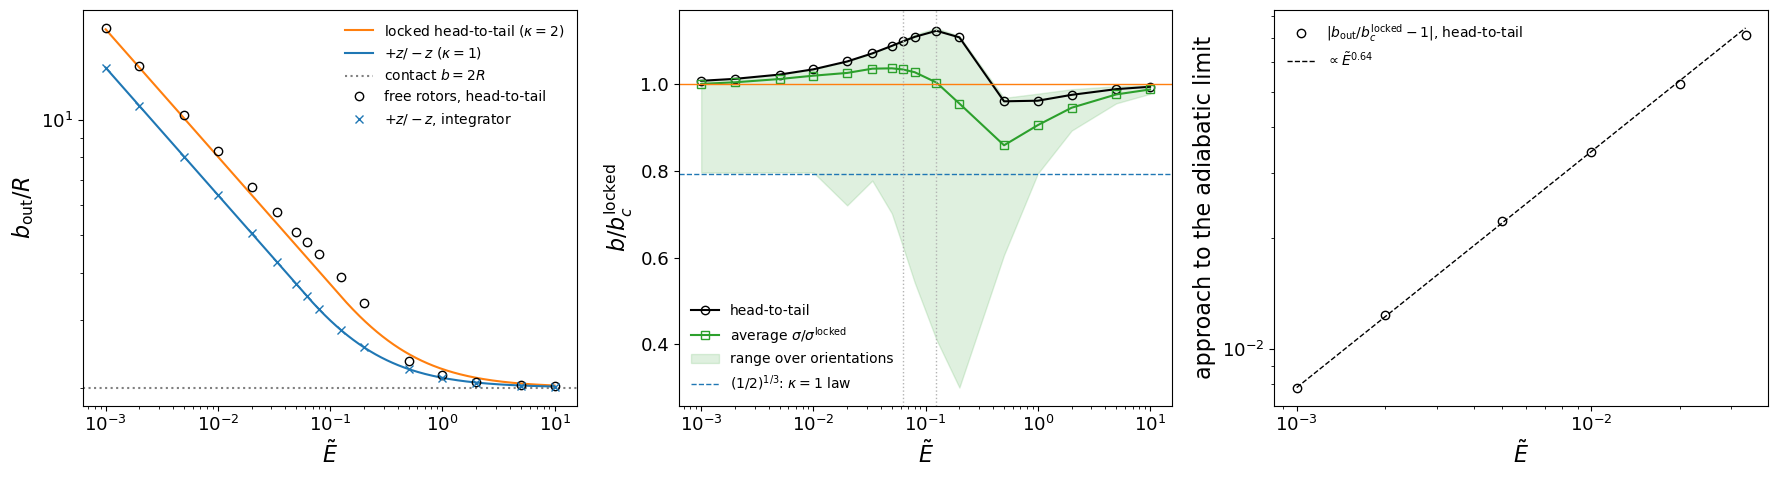

PASS  +z/-z edge vs analytic         max rel err 4.5e-08 over 16 energies (both branches)
PASS  adiabatic limit E -> 0         b_out/b_locked - 1 = +0.0078@0.001, +0.0123@0.002, +0.0222@0.005, +0.0343@0.01
PASS  geometric limit E -> inf       b_out - 2 = 0.1509@1, 0.0691@2, 0.0261@5, 0.0128@10; (b^2-4)E = 0.626, 0.563, 0.525, 0.513
PASS  paper energy head-to-tail      5.7545894 vs stage-5 5.7545902
PASS  paper energy vs map_torus32    interval counts identical: True; max rel b_out diff 5.9e-07
PASS  provenance                     dirty or mixed runs: []; analysis tree dirty: False; run commits ['31bd539c', '86632691']; runtime code differs from 5cd469ac at: []
orientation-grid error (16x16 vs 32x32): max 0.75%;  sigma_meas vs sigma_out: max 0.26%
live head-to-tail edge at E = 0.005: 10.353880 (stored 10.353880)


In [24]:
scan = json.loads((ROOT / "tests" / "reference" / "energy_scan.json").read_text())
rows = scan["rows"]
E = np.array([r["energy"] for r in rows])
fine = np.geomspace(E.min(), E.max(), 400)
lock = np.array([central.capture_impact_parameter(e, 2.0) for e in fine])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
ax1.loglog(fine, lock, "C1-", label=r"locked head-to-tail ($\kappa=2$)")
ax1.loglog(fine, [central.capture_impact_parameter(e, 1.0) for e in fine], "C0-", label=r"$+z/-z$ ($\kappa=1$)")
ax1.axhline(2.0, color="0.5", ls=":", label=r"contact $b=2R$")
ax1.loglog(E, [r["b_head_to_tail"] for r in rows], "ko", mfc="none", label="free rotors, head-to-tail")
ax1.loglog(E, [r["b_zz"] for r in rows], "C0x", label=r"$+z/-z$, integrator")
ax1.set_xlabel(r"$\tilde E$"); ax1.set_ylabel(r"$b_{\rm out}/R$"); ax1.legend(fontsize=10)

ax2.semilogx(E, [r["ratio_locked"] for r in rows], "ko-", mfc="none", label="head-to-tail")
ax2.semilogx(E, [r["sigma_out"] / r["sigma_locked"] for r in rows], "C2s-", mfc="none",
             label=r"average $\sigma/\sigma^{\rm locked}$")
ax2.fill_between(E, [r["b_out_min"] / r["b_locked"] for r in rows], [r["b_out_max"] / r["b_locked"] for r in rows],
                 color="C2", alpha=0.15, label="range over orientations")
ax2.axhline(1.0, color="C1", lw=1)
ax2.axhline(0.5 ** (1 / 3), color="C0", lw=1, ls="--", label=r"$(1/2)^{1/3}$: $\kappa=1$ law")
for e_star in (1 / 16, 1 / 8):
    ax2.axvline(e_star, color="0.7", lw=1, ls=":")
ax2.set_xlabel(r"$\tilde E$"); ax2.set_ylabel(r"$b/b_c^{\rm locked}$"); ax2.legend(fontsize=10, loc="lower left")

low = E < 0.05
ax3.loglog(E[low], [abs(r["ratio_locked"] - 1) for r, keep in zip(rows, low) if keep], "ko", mfc="none",
           label=r"$|b_{\rm out}/b_c^{\rm locked}-1|$, head-to-tail")
slope = np.polyfit(np.log(E[:4]), np.log([rows[k]["ratio_locked"] - 1 for k in range(4)]), 1)[0]
ax3.loglog(E[low], (rows[0]["ratio_locked"] - 1) * (E[low] / E[0]) ** slope, "k--", lw=1,
           label=fr"$\propto\tilde E^{{{slope:.2f}}}$")
ax3.set_xlabel(r"$\tilde E$"); ax3.set_ylabel("approach to the adiabatic limit"); ax3.legend(fontsize=10)
fig.tight_layout(); plt.show()

for c in scan["checks"]:
    print(f"{'PASS' if c['pass'] else 'FAIL'}  {c['name']:30s} {c['detail']}")
print(f"orientation-grid error (16x16 vs 32x32): max {max(abs(r['sigma_out_16'] / r['sigma_out'] - 1) for r in rows) * 100:.2f}%;  "
      f"sigma_meas vs sigma_out: max {max(abs(r['sigma_meas'] / r['sigma_out'] - 1) for r in rows) * 100:.2f}%")

# Live re-check: the head-to-tail edge at one energy, at that energy's scan settings.
sys.path.insert(0, str(ROOT / "analysis"))
from energy_scan import scan_settings
e_chk = 5e-3
cfg = scan_settings(e_chk)
live = capture_profile(e_chk, X_HAT, X_HAT, b_min=0.05, b_max=cfg["b_max"], n_scan=cfg["n_scan"], rel_tol=1e-6,
                       start_radius=cfg["start_radius"], method=FAST)["outer_edge"]
stored = next(r["b_head_to_tail"] for r in rows if r["energy"] == e_chk)
print(f"live head-to-tail edge at E = {e_chk}: {live:.6f} (stored {stored:.6f})")

**What the energy scan shows.**

- **Slow limit ($\tilde E\to0$): the locked law holds, with two branches.**
  - Head-to-tail approaches the locked law as $\tilde E^{\,2/3}$ (fitted exponent $\approx0.64$),
    reaching $b_{\rm out}/b_c^{\rm locked}=1.008$ at $\tilde E=10^{-3}$. The orientation average matches it
    too ($1.0006$).
  - The minimum over orientations is head-to-head, and it approaches $(1/2)^{1/3}$ instead: the
    $\kappa=1$ law. That is what the antiparallel invariant family predicts. Antiparallel moments
    stay antiparallel, so adiabatically they can reach at best side-by-side antiparallel alignment
    ($U=-1/r^3$), never head-to-tail.
- **Intermediate energies: free rotors beat the locked law, then fall below it.**
  - The head-to-tail enhancement grows to $12\%$ at $\tilde E=1/8$, which is the locked law's
    barrier-to-contact crossover. The orientation average peaks near $4\%$ just below it.
  - Above the crossover both fall *below* the locked law. The average reaches $0.86$ at
    $\tilde E\approx0.5$.
  - Escape windows occur only for $0.02\lesssim\tilde E\lesssim0.2$. The $3.1\%$ plateau is one grid
    diagonal ($32/1024$), so that number is limited by the $32\times32$ grid; the band's true extent
    is the stage 8 result.
- **Fast limit ($\tilde E\to\infty$): the geometric edge.** $b_{\rm out}\to2R$. The head-to-tail excess
  behaves like a contact-limited law with an effective coupling $\kappa_{\rm eff}=2(b_{\rm out}^2-4)\tilde E\to1.03$,
  about half the locked value. During a fast pass the moments barely turn, so the head-to-tail
  alignment along the approach axis is not kept at closest approach. That is an interpretation,
  not yet tested.

## 12. The fractal escape-window band versus energy (stage 9)

At the paper energy, the escape windows sit in a band just below the mirror line
$\phi_2=\pi-\phi_1$ (section 10b), and inside it the capture boundary is fractal (section 10d). This
section asks how that band changes with energy: where it lies, how much of the orientation torus
it covers, and whether its boundary stays fractal.

**What was computed** (`analysis/band_scan.py`), at 11 energies from $\tilde E=0.002$ to $0.35$:
- **Mirror strips** in strip coordinates $\phi_1=s$, $\phi_2=\pi-s+d$: 32 rows along the line,
  and a $d$ step of $\pi/512$ ($\pi/2048$ below $\tilde E=0.02$, where the band is narrow). Each
  energy uses its stage-6a settings, plus a copy with a 4× finer $b$ scan. The band statistics
  come from the 4× copy, because thin windows fall between the production scan points.
- **Band measures** per energy:
  - the *sharp edge*, i.e. the largest jump of $b_{\rm out}$ across $d$;
  - the $d$ range of the orientations with windows;
  - the band's share of all in-plane orientations.
- **Uncertainty exponents**, sampled at 50 000 or 20 000 impact parameters per point:
  - a *survey* of 6 window points per row (rows $s=\pi/4$ and $\pi/2$), spread across the band's
    $d$ range, each on a $b$ interval around its windows;
  - the $+z/-z$ control, which has one analytic edge ($\alpha=1$);
  - the antiparallel line at $s=\pi/4$.

The energy range comes from a first one-row probe. The band does not close at low energy: it
narrows and moves toward the mirror line. It closes at high energy: between $\tilde E=0.25$ and $0.28$
at $s=\pi/2$, and between 0.3 and 0.35 in a pocket near head-to-head and tail-to-tail ($s\to0,\pi$).

**Checks** (all pass; printed below):
- **Paper energy:**
  - the strip matches the stage-8c strip to $8\times10^{-7}$, with the same sharp edge in every row;
  - the stage-8 exponent points reproduce their stored counts exactly.
- **Control:** $+z/-z$ gives $\alpha=1.030\pm0.021$ at every energy.
- **4× $b$ scan:**
  - no row's sharp edge moves;
  - $b_{\rm out}$ moves at 81 of 81 248 points, nearly all thin contact slivers found just above
    the production edge next to windows;
  - a 16× scan confirms the 4× value at all 81.
- **Closing:** no windows at $\tilde E=0.35$, even on a 4× finer $d$ grid that includes the corner rows.
- **Stage 6a:** strip points that lie on the $32\times32$ grid reproduce the stage-6a maps
  (816 points, all identical).
- **Provenance:** all runs clean, and the trajectory code unchanged since.

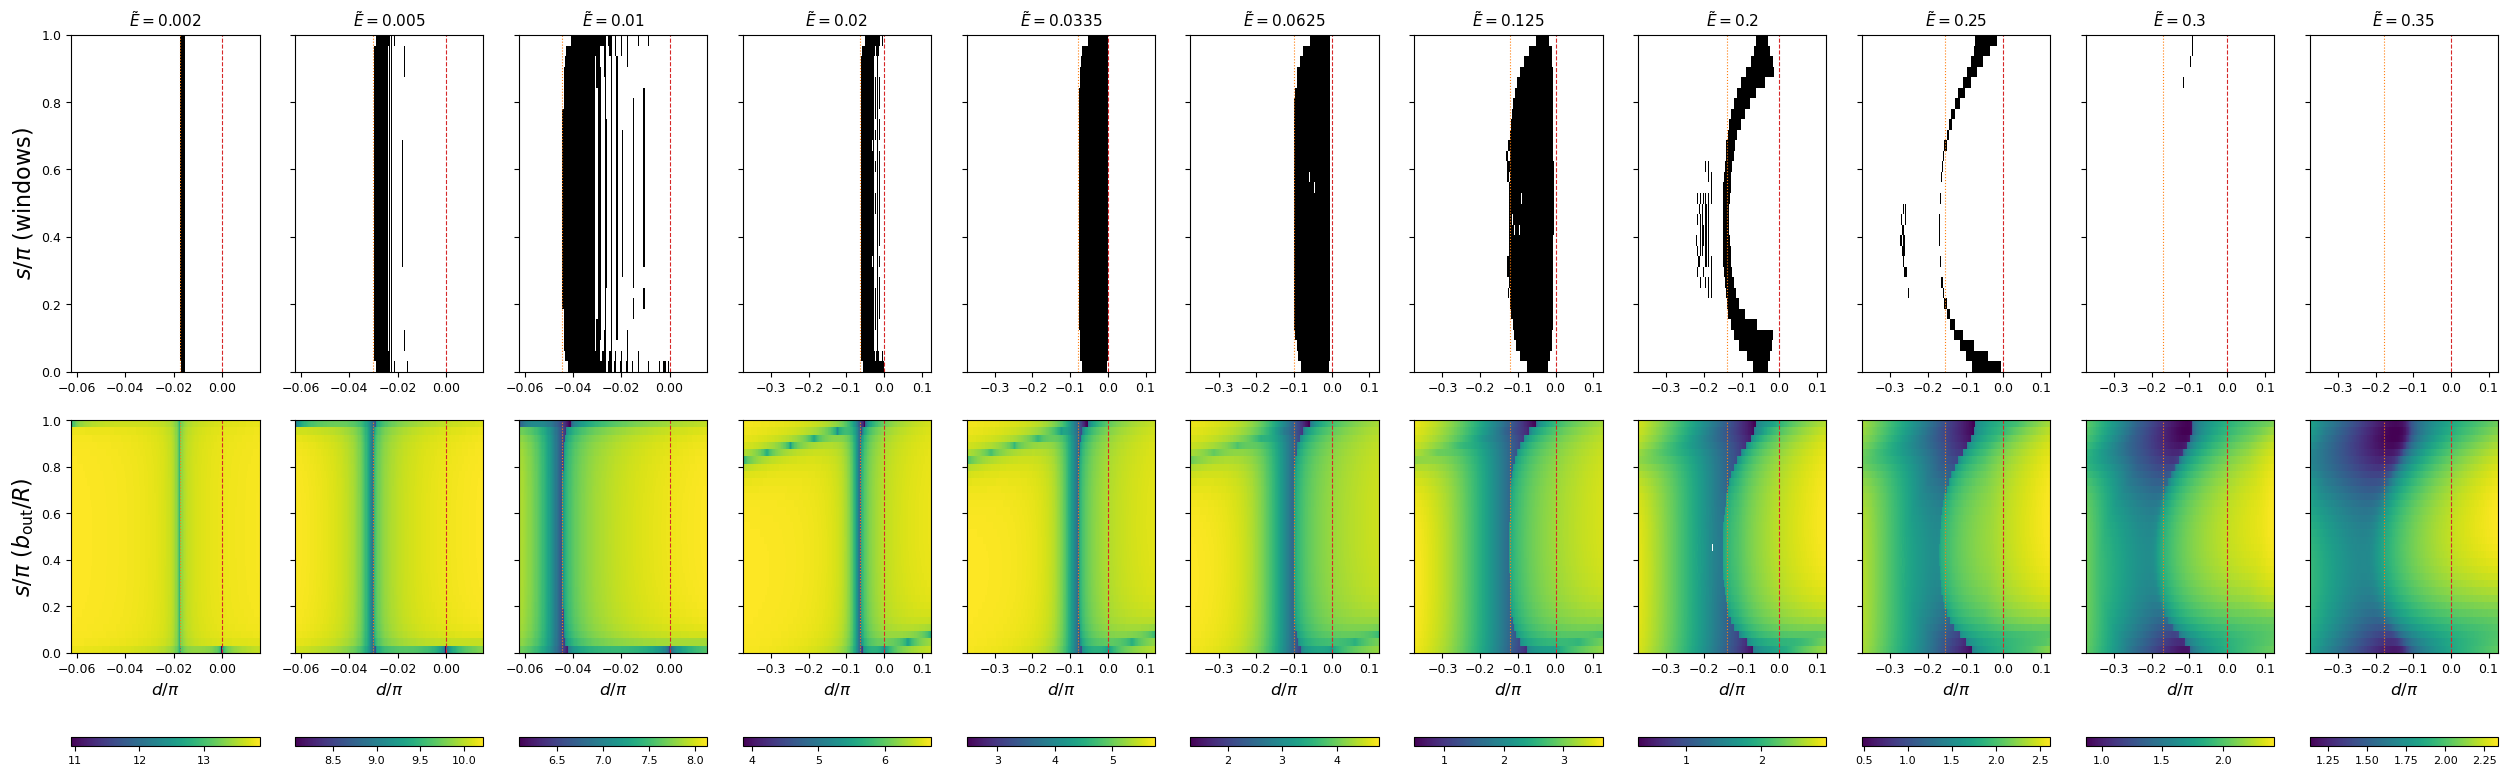

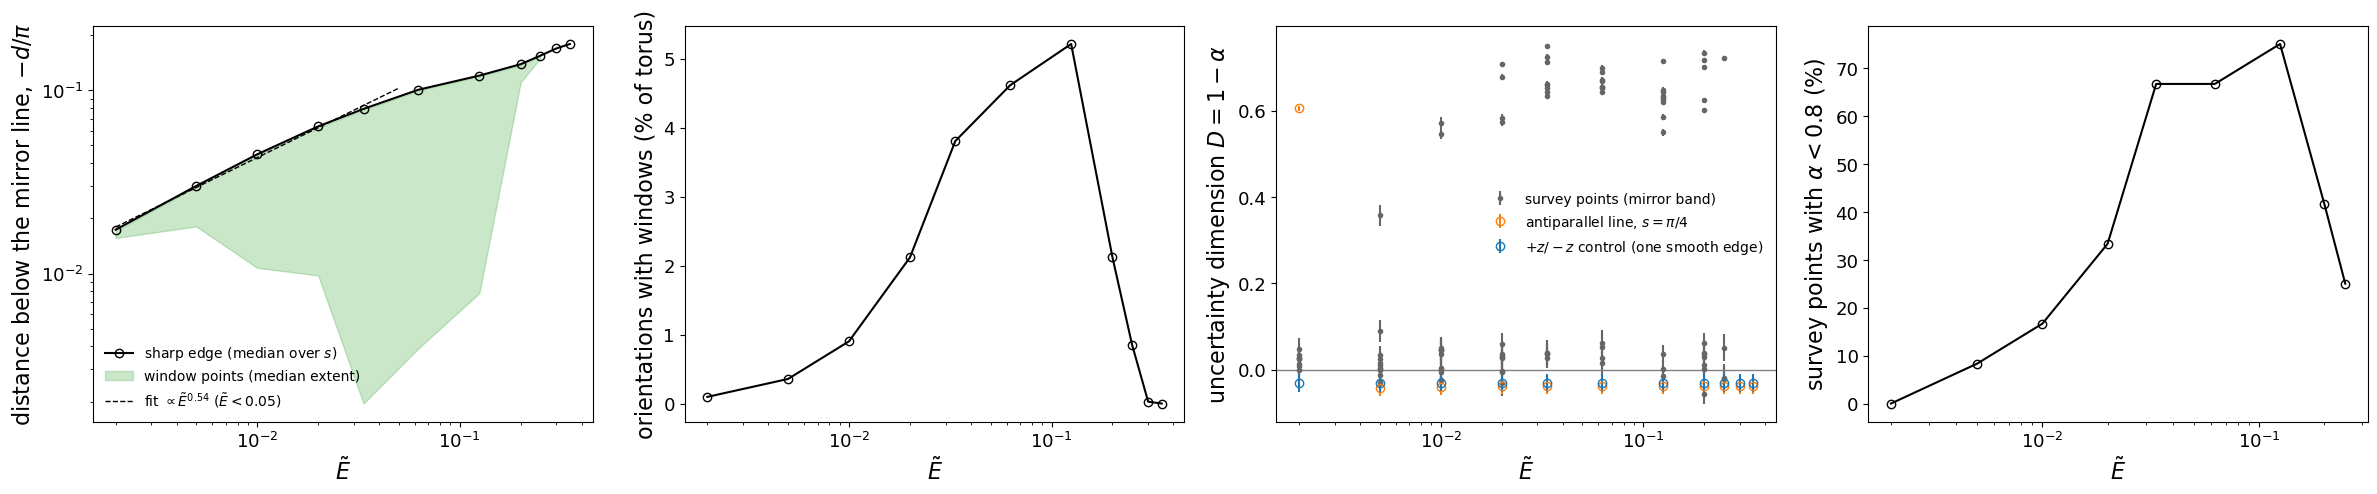

PASS  paper energy vs stage-8c strip   4640 common points, max rel b_out diff 8.2e-07; rows with a different sharp edge: 0 (stage-8c run 088c16f3, clean and complete)
PASS  stage-8 exponents reproduced     band_A: alpha 0.351 vs 0.351, counts identical True, band_B: alpha 0.266 vs 0.266, counts identical True
PASS  +z/-z control alpha = 1          11 controls, alpha 1.030-1.030; outside max(3 sigma, 0.05): []
PASS  anti-line structure is dynamical E = 0.002: uncertain counts production [58, 69, 55]; rtol 1e-12 [61, 56, 59]; 2 r0 [55, 62, 61] of 20000 (within 4 sigma of production)
PASS  4x scan: b_out, sharp edge       b_out moved by > 2e-06 at 81/81248 points (80 contact slivers next to windows, 1 other); 16x confirms the 4x b_out at 81/81 (not at []); rows with a moved sharp edge: {}
PASS  band closes by E = 0.35          window points: 9 at E = 0.3, 0 at 0.35, 0 on the pi/2048 grid at 0.35
PASS  strip vs 32x32 maps (6a)         0.002: 32 pts, 0 mismatches, 0e+00; 0.005: 32 pts, 0 mi


live re-check (E = 0.0335, s = pi/2, d = -0.0820 pi): b_out 3.650477 (stored 3.650477), 1 intervals (stored 1)


In [25]:
band = json.loads((ROOT / "tests" / "reference" / "band_scan.json").read_text())
band_maps = np.load(ROOT / "tests" / "reference" / "band_maps.npz")
rows_b = band["per_energy"]
Eb = np.array([r["energy"] for r in rows_b])
shown = [r for r in rows_b if r["n_window_points"] > 0] + [r for r in rows_b if r["n_window_points"] == 0][:1]

# Band maps: window points (black) over s along the mirror line and d across it, one panel per energy.
fig, axes = plt.subplots(2, len(shown), figsize=(2.3 * len(shown), 8), sharey=True,
                         gridspec_kw={"height_ratios": [1, 1]})
for k, r in enumerate(shown):
    key = f"E{r['energy']:.6g}"
    across = band_maps[f"{key}__across"] / np.pi
    ext = (across[0], across[-1], 0, 1)
    win = band_maps[f"{key}__n_intervals"] >= 2
    axes[0, k].imshow(win, origin="lower", aspect="auto", cmap="Greys", interpolation="nearest", extent=ext)
    im = axes[1, k].imshow(band_maps[f"{key}__outer_edge"], origin="lower", aspect="auto", cmap="viridis",
                           interpolation="nearest", extent=ext)
    for ax in axes[:, k]:
        ax.axvline(0, color="C3", lw=0.8, ls="--")
        ax.axvline(r["sharp_edge"], color="C1", lw=0.8, ls=":")
        ax.tick_params(labelsize=9)
    axes[0, k].set_title(fr"$\tilde E={r['energy']:.3g}$", fontsize=11)
    axes[1, k].set_xlabel(r"$d/\pi$", fontsize=12)
    fig.colorbar(im, ax=axes[1, k], orientation="horizontal", pad=0.25, fraction=0.06).ax.tick_params(labelsize=8)
axes[0, 0].set_ylabel(r"$s/\pi$ (windows)"); axes[1, 0].set_ylabel(r"$s/\pi$ ($b_{\rm out}/R$)")
fig.tight_layout(); plt.show()

# Band position, size and dimension vs energy (window range shaded where the band spans every row).
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(24, 5))
op = [r for r in rows_b if r["rows_with_windows"] == len(r["rows"])]
ax1.loglog(Eb, [-r["sharp_edge"] for r in rows_b], "ko-", mfc="none", label="sharp edge (median over $s$)")
ax1.fill_between([r["energy"] for r in op], [max(-r["window_hi"], 1e-4) for r in op], [-r["window_lo"] for r in op],
                 color="C2", alpha=0.25, label="window points (median extent)")
fit = band["fits"]["sharp_edge_low_E"]
xs = np.geomspace(Eb.min(), 0.05, 50)
ax1.loglog(xs, fit["prefactor_pi"] * xs ** fit["exponent"], "k--", lw=1,
           label=fr"fit $\propto\tilde E^{{{fit['exponent']:.2f}}}$ ($\tilde E<0.05$)")
ax1.set_xlabel(r"$\tilde E$"); ax1.set_ylabel(r"distance below the mirror line, $-d/\pi$"); ax1.legend(fontsize=10)
ax2.semilogx(Eb, [100 * r["torus_fraction"] for r in rows_b], "ko-", mfc="none")
ax2.set_xlabel(r"$\tilde E$"); ax2.set_ylabel("orientations with windows (% of torus)")
surv = [(r["energy"], v) for r in rows_b for v in r["survey"].values()]
ax3.errorbar([e for e, _ in surv], [1 - v["alpha"] for _, v in surv], yerr=[v["alpha_err"] for _, v in surv],
             fmt=".", color="0.4", ms=6, label="survey points (mirror band)")
for kind, color, label in (("anti_line", "C1", r"antiparallel line, $s=\pi/4$"),
                           ("control", "C0", r"$+z/-z$ control (one smooth edge)")):
    pts = [(r["energy"], v) for r in rows_b for v in r["exponents"].values() if v["kind"] == kind]
    ax3.errorbar([e for e, _ in pts], [1 - v["alpha"] for _, v in pts], yerr=[v["alpha_err"] for _, v in pts],
                 fmt="o", color=color, mfc="none", label=label)
ax3.set_xscale("log"); ax3.axhline(0, color="0.5", lw=1)
ax3.set_xlabel(r"$\tilde E$"); ax3.set_ylabel(r"uncertainty dimension $D=1-\alpha$"); ax3.legend(fontsize=10)
sv = [r for r in rows_b if r["survey_fractal_share"] is not None]
ax4.semilogx([r["energy"] for r in sv], [100 * r["survey_fractal_share"] for r in sv], "ko-", mfc="none")
ax4.set_xlabel(r"$\tilde E$"); ax4.set_ylabel(r"survey points with $\alpha<0.8$ (%)")
fig.tight_layout(); plt.show()

for c in band["checks"]:
    print(f"{'PASS' if c['pass'] else 'FAIL'}  {c['name']:32s} {c['detail']}")
print()
for r in rows_b:
    n_s = len(r["survey"])
    frac = "-" if not n_s else f"{round(r['survey_fractal_share'] * n_s)}/{n_s}"
    print(f"E = {r['energy']:<8.4g} sharp edge {r['sharp_edge']:+.4f} pi   windows {r['n_window_points']:5d} points "
          f"({100 * r['torus_fraction']:.2f}% of torus)   fractal survey points {frac}")

# Live re-check: one stored 4x-scan strip point at the paper energy.
from physics.edges import strip_point
meta_b = json.loads(str(band_maps["E0.0335008__meta"]))
rec_b = strip_point(meta_b["settings"]["energy"], 16, 150, meta_b["grid"], meta_b["settings"])
print(f"\nlive re-check (E = {meta_b['settings']['energy']:.4g}, s = pi/2, d = {rec_b['across'] / np.pi:+.4f} pi): "
      f"b_out {rec_b['outer_edge']:.6f} (stored {band_maps['E0.0335008__outer_edge'][16, 150]:.6f}), "
      f"{rec_b['n_intervals']} intervals (stored {band_maps['E0.0335008__n_intervals'][16, 150]})")

**What the band scan shows.**

- **Position: the band follows a power law at low energy.**
  - Its sharp edge lies below the mirror line by $-d\approx0.52\pi\,\tilde E^{0.54}$ (fit for
    $\tilde E<0.05$).
  - It moves toward the mirror line as the energy drops and away from it as the energy rises,
    reaching $0.18\pi$ at $\tilde E=0.35$.
  - Above $\tilde E\approx0.1$ it bends into an arc across $s$ and breaks up. Its last remnant is a
    pocket near head-to-head and tail-to-tail, which survives to $\tilde E=0.3$.
- **Size: the band peaks at the locked law's crossover.**
  - Its share of in-plane orientations grows from 0.1% at $\tilde E=0.002$ to **5.2% at
    $\tilde E=1/8$**. That is the locked law's barrier-to-contact crossover, the same energy where
    the head-to-tail enhancement peaks (section 11).
  - Above it the share falls: 0.85% at 0.25, 0.03% at 0.3 (the pocket), and zero at 0.35.
  - The 32×32 maps saw windows only for $0.02\lesssim\tilde E\lesssim0.2$ because the band is
    narrower than one grid cell outside that range.
- **Fractality: two kinds of boundary, one dimension.**
  - Each surveyed window is either smooth ($\alpha\approx1$) or fractal. Every fractal one has
    $D=1-\alpha\approx0.55$–$0.75$, close to the stage-8 values, at every energy.
  - What changes with energy is **how much of the band is fractal**: 0 of 8 survey points at
    $\tilde E=0.002$, rising to 9 of 12 at $\tilde E=1/8$, then falling to 1 of 4 at 0.25.
  - Below $1/8$ the side next to the sharp edge stays smooth, and the fractal part grows from the
    mirror-line side. From $1/8$ up it is the other way round: the side toward the mirror line is
    smooth, and the fractal windows lie on the far side of the arc.
- **The antiparallel line is not a smooth edge at low energy.**
  - At $\tilde E=0.002$ it has a fat-fractal zone about $2.5\times10^{-3}$ wide just below its outer
    edge, with $\alpha=0.40$. Each 4× finer scan finds 4× more edges, while the capture measure
    changes by only about 1.5%.
  - Tightened numerics (rtol $10^{-12}$, twice $r_0$) change the counts only within counting noise,
    so the structure is dynamical, not numerical.
  - The antiparallel orientations are an invariant family, but unlike $+z/-z$ they are not
    integrable. Near the orbiting edge their scattering is chaotic.
  - From $\tilde E=0.005$ up the zone is too thin for these intervals ($\alpha\approx1.04$).

## 13. Summary of results and next steps

The "Where" column says where each number is measured: a section of this notebook (its printed
output above) or the test suite, for checks that are too slow or too detailed to repeat here.

| Check | Expected | Obtained | Where |
|---|---|---|---|
| force $=-\nabla U$; torque balance | finite differences; machine precision | $1.8\times10^{-9}$; $9\times10^{-16}$ | §1 |
| $+z/-z$ deflection vs quadrature (90 points) | $<10^{-8}$ | $1.1\times10^{-9}$ | §3a |
| large-$b$ limit $2/\tilde{E}b^3$ | correction $\propto b^{-3}$ | yes | §3a (figure) |
| capture edge, both branches (17 energies) | analytic | rel $3.7\times10^{-10}$ (bisection bracket) | §3b |
| orbiting coefficient $d\Theta/d\ln(b-b_c)$ | 1 | 0.9999 | §3c |
| $r_0$ convergence ($+z/-z$) | order 4 | 4.00–4.02 | §3d |
| head-to-tail rotor modes | $\omega^2=3/\tilde{I}d^3,\ 1/\tilde{I}d^3$ | frequency $2.5\times10^{-9}$ | tests (`test_rotation.py`); §4 figure |
| scissor instability, $\alpha=\epsilon\cosh\sigma t$ | $\sigma=1/\sqrt{\tilde{I}d^3}$ | $1.6\times10^{-8}$ over 16 e-folds | §4 |
| generic 3D: $E$, $\mathbf{J}$ | conserved | drift $<10^{-9}$; $\mathbf{L}$ changes 4–40% | §5 (figure) |
| in-state correction | order $1\to2$ | $0.99,\,1.11\to2.03,\,1.96$ (two cases) | §6 |
| orientation map accuracy | refinement-stable | $4.9\times10^{-7}$ (18 points); 4× scan identical | tests / `analysis/`; live re-check §8 |
| $256\times256$ map vs $32\times32$ map (shared points) | identical | rel $0$; interval counts identical | §8; tests (`test_edges.py`) |
| numba vs scipy | same algorithm | same step count; end state $\sim10^{-13}$; ~400–500× faster (timing varies) | §9; full map in tests |
| zoomed strips/patch: $b_{\rm out}$ under a 4× $b$ scan | converged | $\le9.3\times10^{-7}$ (strips, coarse patch); live re-check | §10; `analysis/compare_maps.py` |
| zoomed maps: interval structure under a 4× scan | converged? | **no**: changes at 884/9280 mirror-strip points (thin windows) | §10b; tests `test_zoom.py` |
| uncertainty exponent, controls | $\alpha=1$, $f=2\epsilon/L$ | $0.99\pm0.02$, $0.97\pm0.02$; counts Poisson-consistent | §10d |
| uncertainty exponent, band points | — | $\alpha=0.35,\ 0.27$ ($D\approx0.65,\ 0.73$); robust to rtol, $r_0$ | §10d |
| energy scan: $+z/-z$ edge vs analytic (16 energies) | both branches | max rel $4.5\times10^{-8}$ | §11 |
| energy scan: slow limit, head-to-tail | $b_{\rm out}/b_c^{\rm locked}\to1$ | $1.008$ at $\tilde E=10^{-3}$, $\propto\tilde E^{0.64}$ | §11 |
| energy scan: fast limit | $b_{\rm out}\to2$ | $2.013$ at $\tilde E=10$; $(b^2-4)\tilde E\to0.51$ | §11 |
| energy scan: paper energy | stage-5 edge; stored map | $5.7545894$; map to $5.9\times10^{-7}$ | §11 |
| energy scan: resolution | $2r_0$, tighter rtol, 2× scan; $16\times16$ grid | $\le7.7\times10^{-7}$; grid $\le0.8\%$ | §11 |
| band scan: paper energy | stage-8c strip; stage-8 counts | $8.2\times10^{-7}$, same sharp edges; counts identical | §12 |
| band scan: $+z/-z$ control (11 energies) | $\alpha=1$ | $1.030\pm0.021$ | §12 |
| band scan: 4× and 16× $b$ scan | $b_{\rm out}$, sharp edge converged | sharp edges fixed; 81 slivers, all confirmed at 16× | §12 |
| band scan: closing | no windows at $\tilde E=0.35$ | none, also on the $\pi/2048$ grid | §12 |
| band scan: vs 32×32 maps | identical | 816 points identical | §12 |

**Physics so far.**
- The **$+z/-z$ power law** is reproduced exactly. It is an invariant but unstable manifold:
  near the barrier-limited edge a $10^{-6}$ tilt changes the deflection by order one.
- **Head-to-tail at the paper energy:** the free rotors collide out to $b_c=5.7546R$, 7% beyond
  the locked-dipole prediction.
- **Over in-plane orientations,** the outer collision edge ranges from 4.18 (head-to-head) to
  5.76 (near head-to-tail) on the coarse map; most orientations collide beyond the locked value
  of 5.37.
- **Zoomed maps (stage 8):**
  - Along the invariant antiparallel orientations there is a smooth cusp:
    $b_{\rm out}\approx4.7$ on the line, $\propto|d|^{0.57}$, $5.6^\circ$ wide.
  - Just below the mirror line is a $13.5^\circ$-wide band of escape windows, and inside it the
    **capture boundary is fractal** ($D\approx0.65$–$0.73$, fat).
  - The lowest outer edge, $\approx2.1$, is where the band edge crosses the cusp near
    tail-to-tail.
- **Energy dependence (stage 6a):**
  - At low energy the locked law holds for the average and for head-to-tail. The
    antiparallel family follows the $\kappa=1$ law instead, because its invariance keeps it from
    reaching head-to-tail.
  - Free rotors beat the locked law up to its crossover ($+12\%$ head-to-tail at $\tilde E=1/8$),
    fall below it above (the average reaches $0.86$ at $\tilde E\approx0.5$), and reach the geometric
    edge $2R$ at high energy.
- **The window band vs energy (stage 9):**
  - The band exists from the lowest energy studied (0.002) up to 0.3. Its sharp edge approaches
    the mirror line as $\tilde E^{0.54}$ at low energy.
  - It covers the most orientations, 5.2%, at the locked law's crossover $\tilde E=1/8$.
  - Fractal windows have $D\approx0.55$–$0.75$ at every energy. Their share of the band rises from
    none at 0.002 to three quarters at $1/8$, then falls.
  - The antiparallel family is chaotic near its edge at low energy ($\alpha=0.40$ at 0.002).

**Suggested next steps**
1. Mechanism of the antiparallel cusp ($|d|^{0.57}$): compare trajectories on and just off the
   invariant family; the simple instability picture does not explain its width.
2. Why the fractal share of the band peaks at the locked law's crossover, and what separates
   fractal from smooth windows (orbiting time near the window edges is a candidate).
3. The chaotic zone on the antiparallel line at low energy: its width and exponent against $\tilde E$.
4. Why free rotors fall below the locked law above the crossover, and why the fast-limit
   head-to-tail coupling is $\kappa_{\rm eff}\approx1$.
5. Out-of-plane orientations: the full four-angle space, reduced by the symmetries, including
   the $z\to-z$ mirror of the moment components.